## Environment Setup

The notebook was developed on a Kaggle notebook with a GPU accelerator (P100/T4) and internet access enabled (needed for the `pip install` cells and the pretrained ImageNet encoder weights). It also runs on any other machine with a CUDA GPU if the data are placed in the same folder structure.

**Data:** the Kaggle dataset *Flood Detection (ECTI 2021 by NASA)* (`maelysboudier/ecti-2021`) is attached as an input (*Add Input*). The folder-detection cell in the *Dataset* section below locates the training and validation-release folders automatically.

In [ ]:
!pip install -q segmentation-models-pytorch --no-deps
!pip install -q pretrainedmodels
!pip install -q efficientnet-pytorch
!pip install -q timm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# 1. Standard
import os
import sys
import gc
import json
import copy
import pickle
import zipfile
import random
from glob import glob

# 2. Data Processing & Visualization
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from IPython.display import FileLink
from sklearn.metrics import precision_recall_curve, confusion_matrix, f1_score

# Set up matplotlib for Jupyter
%matplotlib inline

# 3. Deep Learning & Computer Vision
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import albumentations as A

# 4. Seed
def seed_everything(seed=42):
    """
    Sets the seed for full reproducibility across Python, NumPy, and PyTorch.
    """
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # If using multi-GPU
        
# Execute the seed function
seed_everything(42)

## Dataset: ETCI 2021 Flood Detection

Here I am downloading the same data as in the EDA notebook. 

31 regions, 33,405 tiles.

## Downloading Data

In [3]:
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

# find the split folders: .../<split>/<region>/tiles/vv
split_counts = Counter(str(Path(d).parents[2]) for d in glob('/kaggle/input/**/tiles/vv', recursive=True))
print(split_counts)          # split folder -> number of regions; check this looks right

train_dir = next(s for s in split_counts if 'train' in os.path.basename(s).lower())
test_dir = next(s for s in split_counts if any(k in os.path.basename(s).lower() for k in ('val', 'test')))
print('train_dir:', train_dir)
print('test_dir :', test_dir)

# numbers used by the verification further below (taken from the files themselves)
n_listed_train_tiles = len(glob(train_dir + '/*/tiles/vv/*_vv.png'))
n_listed_train_regions = len(glob(train_dir + '/*/'))
n_listed_test_tiles = len(glob(test_dir + '/*/tiles/vv/*_vv.png'))
TILE_FRACTION = 1.0
TEST_TILES = n_listed_test_tiles
n_train_regions, n_test_regions = n_listed_train_regions, len(glob(test_dir + '/*/'))
print(n_listed_train_tiles, 'train tiles |', n_train_regions, 'regions |', n_listed_test_tiles, 'test tiles')

Counter({'/kaggle/input/datasets/maelysboudier/ecti-2021/ecti2021/train/train': 31, '/kaggle/input/datasets/tinasikhbse/flood-detection/ecti2021/train/train': 31, '/kaggle/input/datasets/maelysboudier/ecti-2021/ecti2021/val_without_ref_labels/val': 10, '/kaggle/input/datasets/tinasikhbse/flood-detection/ecti2021/val_without_ref_labels/val': 10})
train_dir: /kaggle/input/datasets/maelysboudier/ecti-2021/ecti2021/train/train
test_dir : /kaggle/input/datasets/maelysboudier/ecti-2021/ecti2021/val_without_ref_labels/val
33405 train tiles | 31 regions | 10400 test tiles


You can skip these funciton, they are the same from EDA notebook

In [6]:
def tile_paths(vv_path):
    """Given the path of a VV image, return the paths of its 3 sibling files:
    (VH image, flood label, water-body label)."""

    # Example: vv_path = ".../tiles/vv/abc_x-0_y-0_vv.png"
    # dirname(vv_path)           -> ".../tiles/vv"
    # dirname(dirname(vv_path))  -> ".../tiles"   (the folder that holds vv, vh, flood_label, water_body_label)
    tiles_dir = os.path.dirname(os.path.dirname(vv_path))

    # File name without the "_vv.png" ending, i.e. the tile's id: "abc_x-0_y-0"
    # All four files of one tile share this id; only the suffix differs.
    stem = os.path.basename(vv_path)[:-len('_vv.png')]

    def pick(folder):
        """Find the label file in `folder`. Label file names differ between dataset copies:
        some are named "<stem>.png", others "<stem>_vv.png". Try both and return the one that exists."""
        for cand in (stem + '.png', stem + '_vv.png'):
            p = os.path.join(tiles_dir, folder, cand)
            if os.path.exists(p):
                return p
        # Neither exists: return the first naming guess anyway.
        # scan_tile() will then see that the file is missing and mark this tile as not ok.
        return os.path.join(tiles_dir, folder, stem + '.png')

    # VH image:  tiles/vh/<stem>_vh.png   (always has the "_vh" suffix, so no guessing is needed)
    # Labels:    found with pick(), because their naming varies
    return os.path.join(tiles_dir, 'vh', stem + '_vh.png'), pick('flood_label'), pick('water_body_label')


# I will scan every tile and build a table tiles_df with the following columns:
SCAN_COLUMNS = [
    'vv_image_path', 'vh_image_path',          # paths of the two radar images (model input)
    'flood_label_path', 'water_body_label_path',  # paths of the two masks
    'ok',                                      # True if all 4 files exist and can be read
    'blank',                                   # True if the whole tile is white (255) = no radar data
    'white_frac',                              # fraction of "no data" pixels (0.0 to 1.0)
    'flood_px',                                # number of flooded pixels in the flood label
    'water_px',                                # number of permanent-water pixels in the water-body label
    'flood_in_void_px',                        # flood-labelled pixels that lie in "no data" areas (suspicious)
    'vv_mean', 'vv_std',                       # mean / std of VV pixel values (helps spot constant tiles)
]


def scan_tile(vv_path):
    """Read all four files of a tile once and record the statistics that I will use in the data analysis below.

    blank            : VV and VH are completely white (255) -> the tile contains no SAR data at all
    white_frac       : share of 'no-data' pixels (VV == 255 and VH == 255)
    flood_px         : number of flood pixels in the flood label
    water_px         : number of water pixels in the water-body label
    flood_in_void_px : flood-labelled pixels that lie inside no-data pixels
    """
    vh, flood, water = tile_paths(vv_path)
    ok = all(os.path.exists(p) for p in (vh, flood, water))
    stats = (False, 0.0, -1, -1, 0, 0.0, 0.0)
    if ok:
        vv_img, vh_img = cv2.imread(vv_path, 0), cv2.imread(vh, 0)
        fl_img, wb_img = cv2.imread(flood, 0), cv2.imread(water, 0)
        if any(x is None for x in (vv_img, vh_img, fl_img, wb_img)):
            ok = False
        else:
            void = (vv_img == 255) & (vh_img == 255)
            stats = (bool(void.all()), float(void.mean()), int((fl_img > 0).sum()), int((wb_img > 0).sum()),
                     int(((fl_img > 0) & void).sum()), float(vv_img.mean()), float(vv_img.std()))
    return (vv_path, vh, flood, water, ok) + stats


def scan_split(split_dir):
    vv_paths = sorted(glob(os.path.join(split_dir, '*', 'tiles', 'vv', '*_vv.png')))
    with ThreadPoolExecutor(max_workers=16) as ex:
        rows = list(tqdm(ex.map(scan_tile, vv_paths), total=len(vv_paths), desc=os.path.basename(split_dir)))
    df = pd.DataFrame(rows, columns=SCAN_COLUMNS)
    df['region'] = [Path(p).parents[2].name for p in df['vv_image_path']]
    return df

Just downloading tiles as before

In [7]:
# One pass over the training tiles
INDEX_CSV = 'train_tile_index.csv'
n_on_disk = len(glob(os.path.join(train_dir, '*', 'tiles', 'vv', '*_vv.png')))
tiles_df = None
if os.path.exists(INDEX_CSV):
    cached = pd.read_csv(INDEX_CSV)
    if (len(cached) == n_on_disk and set(SCAN_COLUMNS) <= set(cached.columns)
            and cached['vv_image_path'].str.startswith(train_dir).all()):
        tiles_df = cached
if tiles_df is None:
    tiles_df = scan_split(train_dir)
    tiles_df.to_csv(INDEX_CSV, index=False)

n_broken = int((~tiles_df['ok']).sum())
print(f'Training tiles indexed: {len(tiles_df)} ({n_broken} incomplete or unreadable tiles dropped)')
tiles_df = tiles_df[tiles_df['ok']].reset_index(drop=True)
tiles_df.head()

train:   0%|          | 0/33405 [00:00<?, ?it/s]

Training tiles indexed: 33405 (0 incomplete or unreadable tiles dropped)


,vv_image_path,vh_image_path,flood_label_path,water_body_label_path,ok,blank,white_frac,flood_px,water_px,flood_in_void_px,vv_mean,vv_std,region
0,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,True,False,0.705963,0,0,0,180.020599,116.180190,bangladesh_20170314t115609
1,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,True,False,0.857803,0,0,0,218.739853,89.059190,bangladesh_20170314t115609
2,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,True,False,0.869659,0,0,0,221.763153,85.852827,bangladesh_20170314t115609
3,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,True,False,0.880981,0,0,0,224.650269,82.571638,bangladesh_20170314t115609
4,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,True,False,0.891663,0,0,0,227.373962,79.255546,bangladesh_20170314t115609


### Utils functions

In [33]:
def visualize(df_row, figsize=[25, 15]):
    # plotting function for data before training, it look at whole row of a dataframe including the labels

    # get image paths
    vv_image_path = df_row['vv_image_path']
    vh_image_path = df_row['vh_image_path']
    flood_label_path = df_row['flood_label_path']
    water_body_label_path = df_row['water_body_label_path']

    # create RGB image from S1 images
    rgb_name = get_filename(vv_image_path)
    vv_image = cv2.imread(vv_image_path, 0) / 255.0
    vh_image = cv2.imread(vh_image_path, 0) / 255.0
    rgb_image = s1_to_rgb(vv_image, vh_image)

    # get water body label mask
    water_body_label_image = cv2.imread(water_body_label_path, 0) / 255.0

    # plot images
    plt.figure(figsize=tuple(figsize))
    if df_row.isnull().sum() > 0:
        # plot RGB S1 image
        plt.subplot(1,2,1)
        plt.imshow(rgb_image)
        plt.title(rgb_name)

        # plot water body mask
        plt.subplot(1,2,2)
        plt.imshow(water_body_label_image)
        plt.title('Water body mask')
    else:
        flood_label_image = cv2.imread(flood_label_path, 0) / 255.0
        # plot RGB S1 image
        plt.subplot(1,3,1)
        plt.imshow(rgb_image)
        plt.title(rgb_name)

        # plot flood label mask
        plt.subplot(1,3,2)
        plt.imshow(flood_label_image)
        plt.title('Flood mask')

        # plot water body mask
        plt.subplot(1,3,3)
        plt.imshow(water_body_label_image)
        plt.title('Water body mask')

def s1_to_rgb(vv_image, vh_image):
    # creates rgb from 2D
    eps=1e-06
    ratio_image = np.clip(np.nan_to_num(vv_image/(vh_image+eps), 0), 0, 1) # outside [0,1] will be clipped
    rgb_image = np.stack((vv_image, vh_image, ratio_image), axis=2) # third channel: VV/VH ratio, clipped to [0, 1]
    return rgb_image

def visualize_result(df_row, prediction, figsize=[25, 15]):
    # just plots an image after training. So prediciton inference
    vv_image = cv2.imread(df_row['vv_image_path'], 0) / 255.0
    vh_image = cv2.imread(df_row['vh_image_path'], 0) / 255.0
    rgb_input = s1_to_rgb(vv_image, vh_image)

    plt.figure(figsize=tuple(figsize))
    plt.subplot(1,2,1)
    plt.imshow(rgb_input)
    plt.title('RGB w/ result')
    plt.subplot(1,2,2)
    plt.imshow(prediction)
    plt.title('Result')

### Cleaning: removing blank tiles

Based on the evidence in the EDA notebook, I remove tiles whose VV and VH images are completely white. The remaining tiles are split into **water tiles** (the flood label contains at least one flood pixel) and **background tiles** (empty flood label).

In [8]:
n_raw = len(tiles_df)
clean_df = tiles_df[~tiles_df['blank']].reset_index(drop=True)
water_df_all = clean_df[clean_df['flood_px'] > 0]
background_df_all = clean_df[clean_df['flood_px'] == 0]

print(f'Training tiles (raw):                 {n_raw}')
print(f'Blank tiles removed:                  {n_raw - len(clean_df)}')
print(f'Tiles after cleaning:                 {len(clean_df)}')
print(f'  water tiles (flood label not empty): {len(water_df_all)}')
print(f'  background tiles:                    {len(background_df_all)}')

Training tiles (raw):                 33405
Blank tiles removed:                  6191
Tiles after cleaning:                 27214
  water tiles (flood label not empty): 10462
  background tiles:                    16752


#### Class distribution before and after cleaning

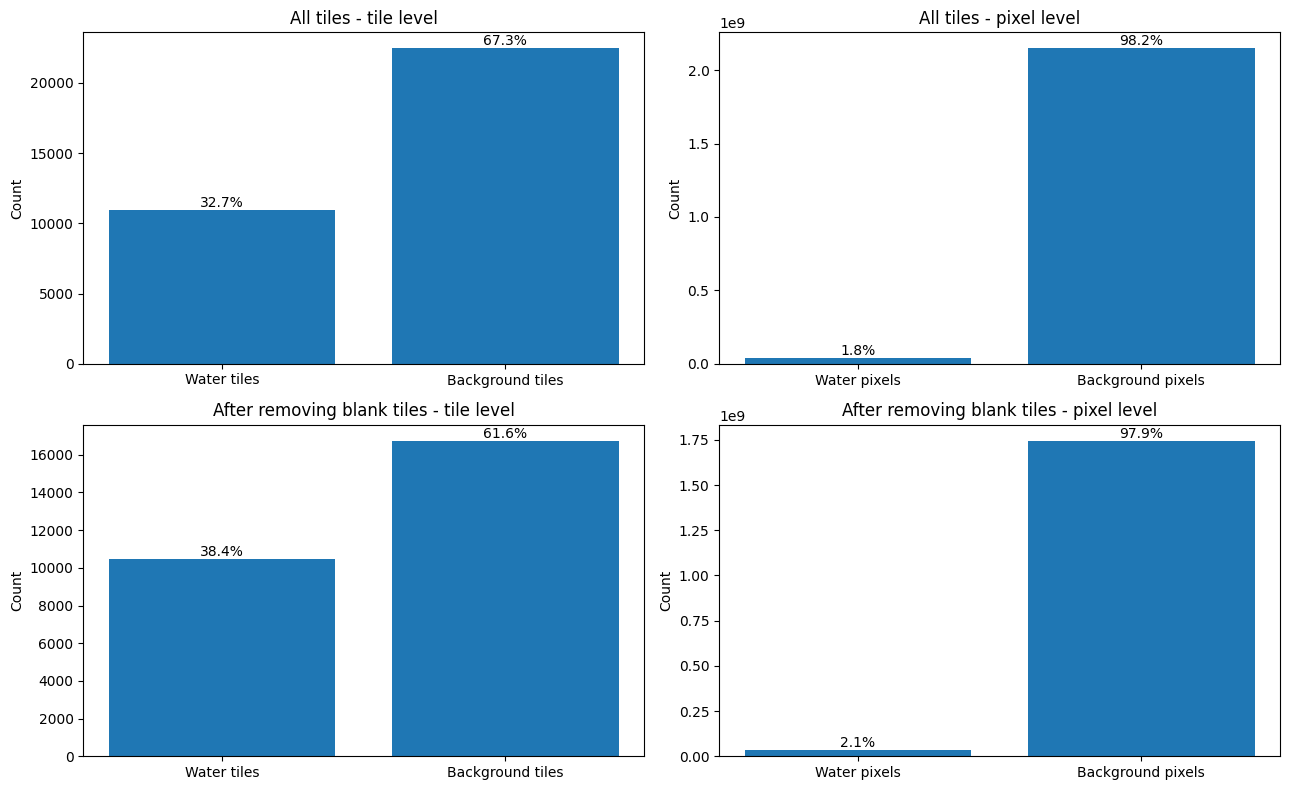

Pixel-level imbalance, all tiles:            55 background pixels per flood pixel
Pixel-level imbalance, blank tiles removed:  47 background pixels per flood pixel


In [15]:
def plot_class_distribution(counts, labels, title, ax=None):
    """Plot a labeled bar chart with percentage annotations."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(2, 2))
    bars = ax.bar(labels, counts)
    total = sum(counts)
    for bar, count in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{100 * count / total:.1f}%", ha="center", va="bottom")
    ax.set_title(title)
    ax.set_ylabel("Count")
    return ax


PIXELS_PER_TILE = 256 * 256
n_flood_px_all = int(clean_df['flood_px'].sum())
n_bg_px_all = len(clean_df) * PIXELS_PER_TILE - n_flood_px_all
n_flood_px_raw = int(tiles_df['flood_px'].sum())
n_bg_px_raw = len(tiles_df) * PIXELS_PER_TILE - n_flood_px_raw
n_water_raw = int((tiles_df['flood_px'] > 0).sum())

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_class_distribution([n_water_raw, len(tiles_df) - n_water_raw], ['Water tiles', 'Background tiles'],
                        'All tiles - tile level', axes[0, 0])
plot_class_distribution([n_flood_px_raw, n_bg_px_raw], ['Water pixels', 'Background pixels'],
                        'All tiles - pixel level', axes[0, 1])
plot_class_distribution([len(water_df_all), len(background_df_all)], ['Water tiles', 'Background tiles'],
                        'After removing blank tiles - tile level', axes[1, 0])
plot_class_distribution([n_flood_px_all, n_bg_px_all], ['Water pixels', 'Background pixels'],
                        'After removing blank tiles - pixel level', axes[1, 1])
plt.tight_layout()
plt.show()
print(f'Pixel-level imbalance, all tiles:            {n_bg_px_raw / n_flood_px_raw:.0f} background pixels per flood pixel')
print(f'Pixel-level imbalance, blank tiles removed:  {n_bg_px_all / n_flood_px_all:.0f} background pixels per flood pixel')

## Create training dataframes

In [16]:
def get_filename(filepath, split_symbol='/'):
    return filepath.split(split_symbol)[-1]

In [17]:
# Water tiles first, then background tiles
water_df = water_df_all
background_df = background_df_all
ordered_df = pd.concat([water_df, background_df])

vv_image_paths = ordered_df['vv_image_path'].tolist()
vh_image_paths = ordered_df['vh_image_path'].tolist()
flood_label_paths = ordered_df['flood_label_path'].tolist()
water_body_label_paths = ordered_df['water_body_label_path'].tolist()

water_image_paths = water_df['vv_image_path'].tolist()
background_image_paths = background_df['vv_image_path'].tolist()

print('Water tiles:', len(water_image_paths), '| Background tiles:', len(background_image_paths))

Water tiles: 10462 | Background tiles: 16752


80% train and 20% validation

In [18]:
#Shuffle the index and then split in train and validation
n=len(vv_image_paths) #number of images in the dataset
arr = np.arange(n) #array 0...n-1
np.random.shuffle(arr) # shuffle it
train_idx=arr[0:int(np.round(0.80*n))] #80% train
valid_idx=arr[int(np.round(0.80*n)):] #20% validation
print("Number of tiles in training set:",train_idx.size)
print("Number of tiles in validation set:",valid_idx.size)
print("Number of tiles in the training and validation set:",train_idx.size+valid_idx.size) 

Number of tiles in training set: 21771
Number of tiles in validation set: 5443
Number of tiles in the training and validation set: 27214


creating the df

In [19]:
vv_image_paths_train = list(np.array(vv_image_paths)[train_idx])
vh_image_paths_train = list(np.array(vh_image_paths)[train_idx])
flood_label_paths_train = list(np.array(flood_label_paths)[train_idx])
water_body_label_paths_train = list(np.array(water_body_label_paths)[train_idx])

train_paths = {'vv_image_path': vv_image_paths_train,
        'vh_image_path': vh_image_paths_train,
        'flood_label_path': flood_label_paths_train,
        'water_body_label_path': water_body_label_paths_train,
}

train_df = pd.DataFrame(train_paths)

print(train_df.shape)
train_df.head()

(21771, 4)


,vv_image_path,vh_image_path,flood_label_path,water_body_label_path
0,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
1,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
2,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
3,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
4,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...


In [20]:
vv_image_paths_valid = list(np.array(vv_image_paths)[valid_idx])
vh_image_paths_valid = list(np.array(vh_image_paths)[valid_idx])
flood_label_paths_valid = list(np.array(flood_label_paths)[valid_idx])
water_body_label_paths_valid = list(np.array(water_body_label_paths)[valid_idx])

valid_paths = {'vv_image_path': vv_image_paths_valid,
        'vh_image_path': vh_image_paths_valid,
        'flood_label_path': flood_label_paths_valid,
        'water_body_label_path': water_body_label_paths_valid,
}


valid_df = pd.DataFrame(valid_paths)

print(valid_df.shape)
valid_df.head()

(5443, 4)


,vv_image_path,vh_image_path,flood_label_path,water_body_label_path
0,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
1,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
2,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
3,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
4,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...


Because we have very severe class imbalance, I will use undersamplig technique

## Create training undersampled dataframes

In the original dataset, there is a severe class imbalance heavily favoring the negative/majority class (background/non-water). Because flood events and permanent water bodies only cover a small fraction of the total area, the vast majority of the tiles and pixels represent normal background land. If a model were trained directly on this highly imbalanced data, it would likely suffer from predictive bias. It could achieve a high accuracy simply by predicting the majority class ("no water") everywhere, while failing to detect the actual minority class (floods/water) which is the primary objective of the model.

To mitigate this bias, I will apply an undersampling technique to the majority class. Specifically, the preserve all of the available positive class examples (water_num_train) but dropped high number of background tiles.
This way, the dataset shifts from being dominated by background land to being composed of water/flood tiles.

This prevents the network from defaulting to "background" predictions and forces the model to focus on extracting and learning the distinct features, edges, and signatures of water and flooded areas.

After removing blank tiles, flood is only ~2.1% of all pixels (see class distribution plot), and even inside a flood tile it is only ~5.5%. So I keep ALL water tiles and drop most background tiles.
With 15%, the flood share rises from ~2.1% to ~4.8% of pixels, but some background is still left so the model can learn what "no flood" looks like.
So for now I will choose 15%

In [21]:
train_path_set = set(vv_image_paths_train)
background_image_paths_train = [path for path in background_image_paths if path in train_path_set]
background_num_train = len(background_image_paths_train)
print('Number of background tiles included in training:',background_num_train)

water_image_paths_train = [path for path in water_image_paths if path in train_path_set]
water_image_names_train = [get_filename(pth) for pth in water_image_paths_train]
region_name_dates2 = ['_'.join(n.split('_')[:2]) for n in water_image_names_train]
water_num_train = len(water_image_paths_train)
print('Number of water tiles included in training:',water_num_train)

Number of background tiles included in training: 13334
Number of water tiles included in training: 8437


In [27]:
num_samples = int(water_num_train * 0.15)  # keep as many background tiles as 15% of the water tiles

# Random sample over ALL background training tiles (the tile list is sorted by region, so taking the
# first N tiles would only cover the first few regions)
rng = np.random.default_rng(42)
sel = rng.choice(len(background_image_paths_train), size=num_samples, replace=False)
background_image_paths_train_undersampled = [background_image_paths_train[i] for i in sel]
print('Number of background tiles included in training after undersampling:', len(background_image_paths_train_undersampled))

# Undersampled training set = all water tiles + the sampled background tiles 
vv_image_paths_train_undersampled = list(water_image_paths_train) + background_image_paths_train_undersampled

tile_lookup = clean_df.set_index('vv_image_path')
vh_image_paths_train_undersampled = tile_lookup.loc[vv_image_paths_train_undersampled, 'vh_image_path'].tolist()
flood_label_paths_train_undersampled = tile_lookup.loc[vv_image_paths_train_undersampled, 'flood_label_path'].tolist()
water_body_label_paths_train_undersampled = tile_lookup.loc[vv_image_paths_train_undersampled, 'water_body_label_path'].tolist()

assert len(vv_image_paths_train_undersampled)==len(vh_image_paths_train_undersampled)==len(flood_label_paths_train_undersampled)==len(water_body_label_paths_train_undersampled)
print('Number of overall images  included in training after undersampling:', len(water_body_label_paths_train_undersampled))

Number of background tiles included in training after undersampling: 1265
Number of overall images  included in training after undersampling: 9702


In [28]:
train_paths_undersample = {'vv_image_path': vv_image_paths_train_undersampled,
        'vh_image_path': vh_image_paths_train_undersampled,
        'flood_label_path': flood_label_paths_train_undersampled,
        'water_body_label_path': water_body_label_paths_train_undersampled
}
train_df_undersample = pd.DataFrame(train_paths_undersample)

print(train_df_undersample.shape)
train_df_undersample.head() 

(9702, 4)


,vv_image_path,vh_image_path,flood_label_path,water_body_label_path
0,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
1,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
2,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
3,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
4,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...


## Visualize images

Visual inspection of a few tiles (SAR false-colour image, flood mask and permanent water-body mask).

In [29]:
train_df

,vv_image_path,vh_image_path,flood_label_path,water_body_label_path
0,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
1,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
2,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
3,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
4,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
...,...,...,...,...
21766,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
21767,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
21768,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...
21769,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...


In [30]:
cv2.imread(train_df_undersample.iloc[1200]['vv_image_path'],0)

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

In [31]:
train_df_undersample.iloc[3600]['vv_image_path']

'/kaggle/input/datasets/maelysboudier/ecti-2021/ecti2021/train/train/northal_20190302t234651/tiles/vv/northal_20190302t234651_x-12_y-11_vv.png'

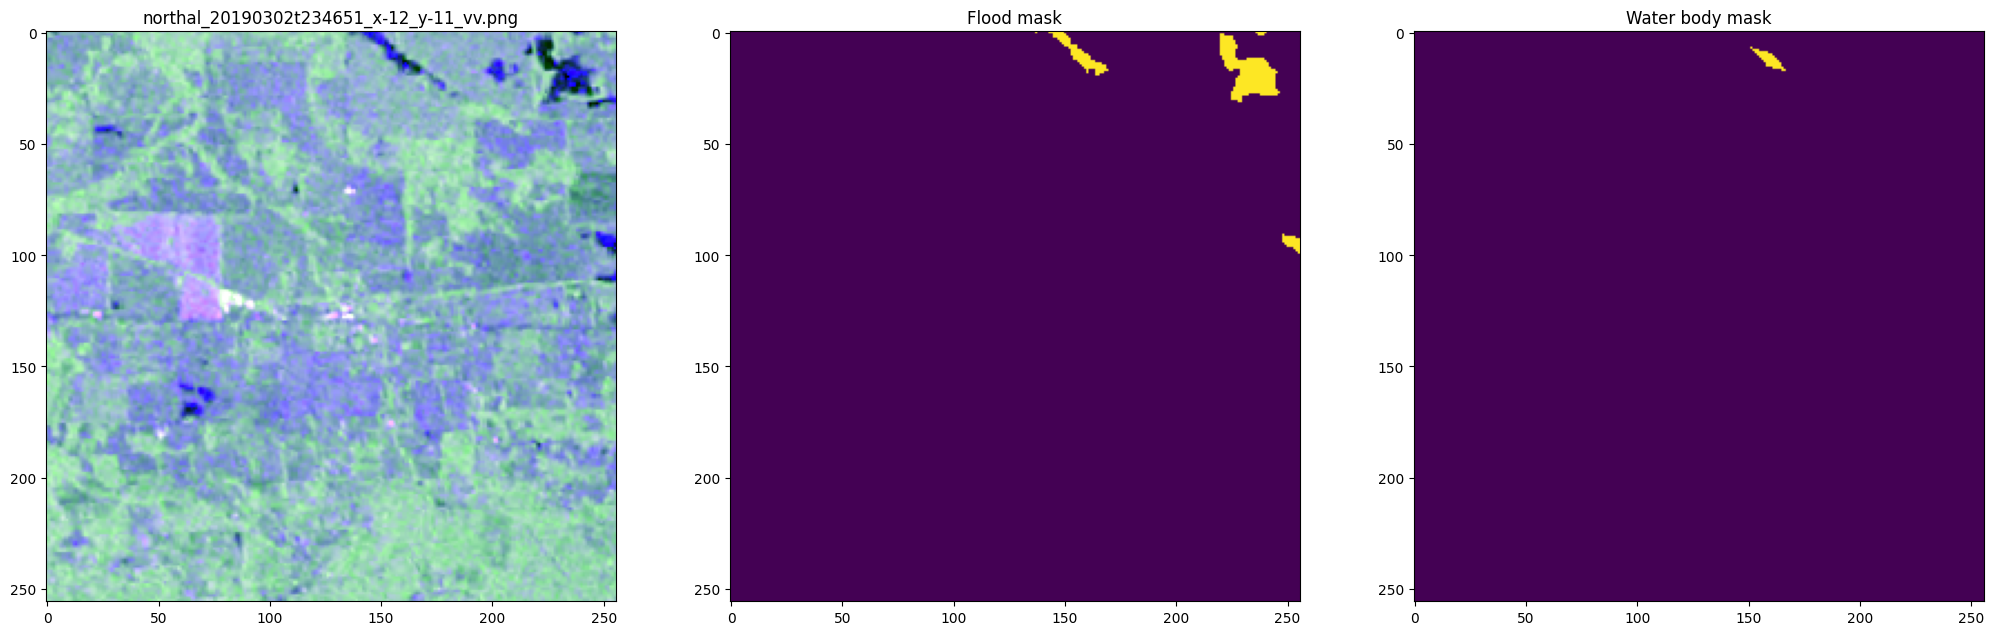

In [34]:
visualize(train_df_undersample.iloc[3600])

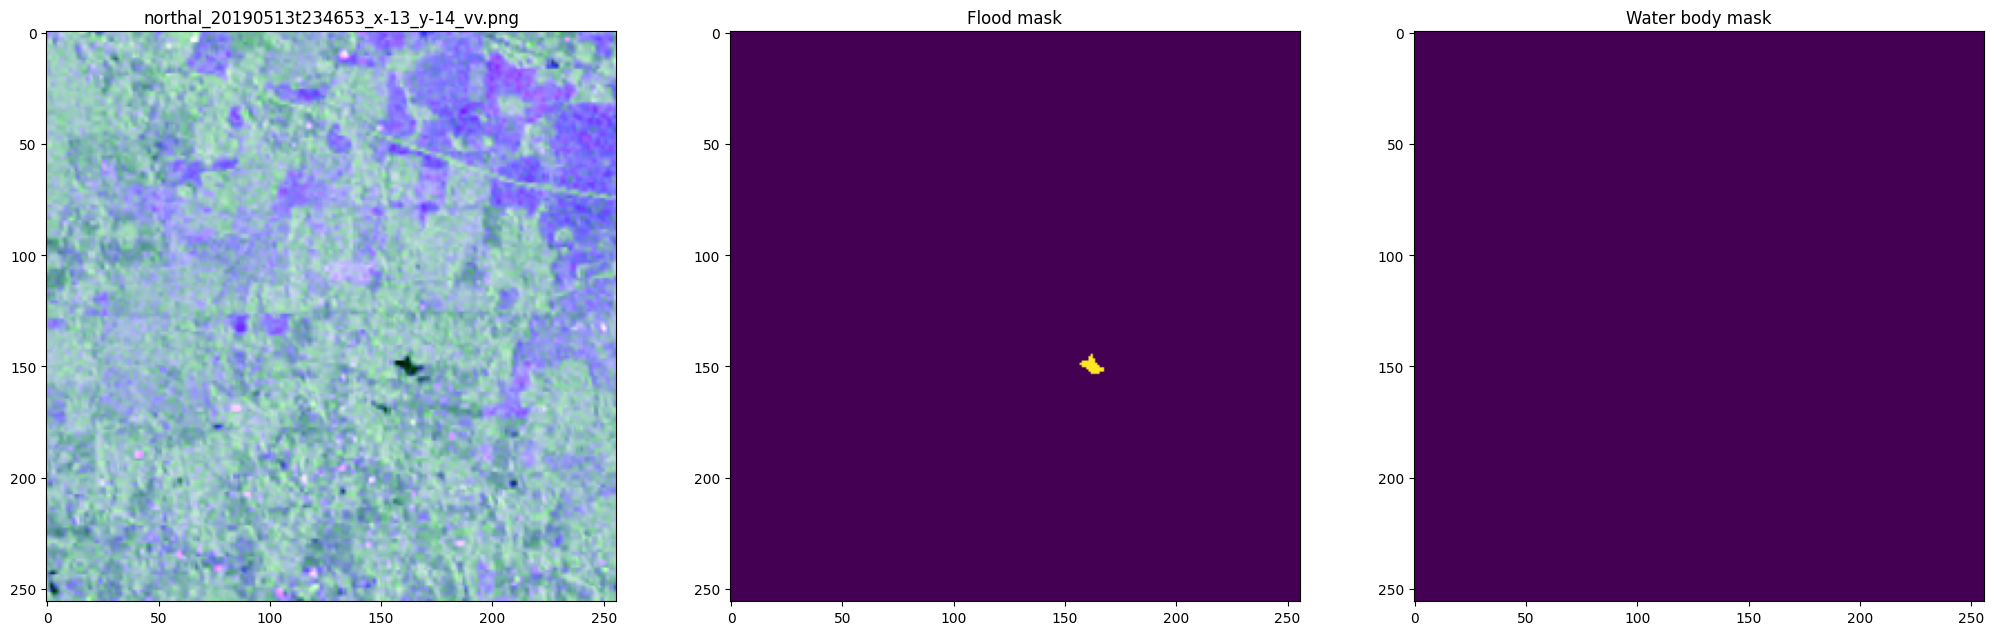

In [35]:
visualize(train_df.iloc[3677])

## Setup the dataset for machine learning

### Create a PyTorch dataset

I will use the **PyTorch** deep learning library to format the dataset and build the model. This requires a custom `Dataset` class passed into a `DataLoader` object 
I will also use image transformations computed using the [Albumentations] package.

In [36]:
class ETCIDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # 1. Retrieve paths
        row = self.df.iloc[idx]
        vv_path = row['vv_image_path']
        vh_path = row['vh_image_path']
        flood_path = row['flood_label_path']
        
        # 2. Read and normalize SAR images
        vv_image = cv2.imread(vv_path, 0) / 255.0
        vh_image = cv2.imread(vh_path, 0) / 255.0
        
        # 3. Create 3-channel image (Format: H x W x 3)
        image = s1_to_rgb(vv_image, vh_image).astype(np.float32)
        
        # 4. Read and normalize mask (Format: H x W)
        mask = cv2.imread(flood_path, 0) / 255.0
        mask = mask.astype(np.float32)

        # 5. Apply Augmentations
        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        # 6. FINAL FORMATTING 
        
        # Image: (H, W, 3) -> (3, H, W)
        image = torch.from_numpy(image.transpose(2, 0, 1)).float()
        
        # Mask: (H, W) -> (1, H, W)
        mask = torch.from_numpy(mask).unsqueeze(0).float()
            
        return image, mask

### Augmentation for SAR imagery

**Not Used**

Standard color-based augmentations (like ColorJitter, RandomBrightnessContrast, or adding artificial lighting/shadows) do not apply and I don't think should be used on SAR data. In optical imagery, changing the brightness mimics different times of day or camera settings without changing the object itself. However, SAR pixels are strict physical measurements of radar backscatter. For example, water has a very low backscatter, because it reflects radar energy away like a mirror. If we were to artificially increase the "brightness" of a water pixel, we would change the data to make it look like dry land or a building.

**OK**

I think spatial and geometric transformations such as Flips, Rotations (by 90-degree increments) are valid. As satellites capture data from space, meaning the absolute orientation of a river, flooded field, or lake on the screen is entirely arbitrary. A flood looks the same if the image is flipped upside down or rotated sideways.

**Augmentations used:**

In the pipeline below, I include:

HorizontalFlip(p=0.5) & VerticalFlip(p=0.5): Flips the image across the x and/y axes. This will teach the model that the direction a river or a flood expands does not dictate whether it is water.

RandomRotate90(p=0.5): Rotates the image by 0, 90, 180, or 270 degrees. I stick to 90-degree rotations instead of arbitrary angles (like 37 degrees) to avoid creating black borders or triggering pixel-interpolation artifacts that might distort the raw SAR values.

I decided to train 2 models, one with whole data and then second with undersampled data. To show you the effect of undersampling.

In [37]:
# Define the augmentation pipeline (Applied only to Training)
transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5)
])

# Create the training dataset for Model 1 (Using the FULL train_df)
train_dataset = ETCIDataset(train_df, transform=transform)

# Create the validation dataset (Always the same for all models)
valid_dataset = ETCIDataset(valid_df, transform=None)

print(f'Model 1 Training set size (Full): {len(train_dataset)}')
print(f'Validation set size: {len(valid_dataset)}')

Model 1 Training set size (Full): 21771
Validation set size: 5443


I chose batch size of 64 because images are 256x256 and that would fit in the memory of a Kaggle GPU

Also it is large enough for U-Net + ResNet34 (which I will use) to give reasonably stable gradients.

I do not tune because lack of the time.

In [38]:
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

In [51]:
train_undersampled_dataset = ETCIDataset(train_df_undersample, transform=transform)
train_undersampled_loader = DataLoader(train_undersampled_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
print('Undersampled Trainining set size:',len(train_undersampled_dataset))

Undersampled Trainining set size: 9702


## Deep learning model creation

In [39]:
device = 'cuda' 

### My Justification for models

**1. Encoder choice:**
I have chosen **ResNet34** as the encoder. In semantic segmentation, there is a trade-off between model capacity (depth) and computational efficiency. ResNet34 provides a strong balance: it is deep enough to learn complex spatial features and structures (like the winding shapes of rivers or flooded areas), but lightweight enough to train efficiently on the available Kaggle GPU without easily overfitting to my relatively small dataset. Heavier encoders (like ResNet101) would consume significantly more memory and training time with diminishing returns.

**2. Pretrained weights:**
I will use **ImageNet** pretrained weights. While there is a massive domain gap between natural optical images (ImageNet) and radar backscatter data (SAR), I expect that transfer learning will be still beneficial. The earliest layers of a Convolutional Neural Network learn fundamental, low-level visual features such as edges, lines, corners, and basic textures. Even though SAR data represents reflectance rather than visible light, flooded regions and rivers still possess distinct edges, boundaries, and textures. Initializing with ImageNet weights provides the network with these foundational feature-detectors, leading to faster convergence and better overall performance compared to starting from random weight initialization.

**3. Number of input channels and output classes:**
* **Input Channels:** **3**. Although raw SAR data is dual-polarization (VV and VH), my `ETCIDataset` implementation utilizes the `s1_to_rgb` utility function to stack VV, VH, and a calculated VV/VH ratio into a 3-channel pseudo-RGB image. 
* **Output Classes:** **1**. This is a binary classification task at the pixel level (Flood vs. No Flood). The model will output a single probability map (a 1-channel mask) where values closer to 1 indicate the presence of water, which perfectly aligns with using a Binary Cross Entropy (BCE) loss function.

I will test 4 different models and analyze the results:
> Models 1 and 2 use this single-channel head with `BCEWithLogitsLoss`. 

> Models 3 uses `CrossEntropyLoss`, which needs one logit per class, so they are created with `create_model(num_classes=2)`.

In [40]:
def create_model(num_classes=1, encoder_weights="imagenet"):
    """
    Creates and returns a U-Net model with a ResNet34 encoder.

    num_classes=1 -> single logit per pixel (BCEWithLogitsLoss, Models 1 and 2)
    num_classes=2 -> one logit per class (CrossEntropyLoss, Models 3 and 4)
    encoder_weights=None skips the ImageNet download (used when the weights
    are loaded from a checkpoint anyway, e.g. for ONNX export).
    """
    model = smp.Unet(
        encoder_name="resnet34",              # Use ResNet34
        encoder_weights=encoder_weights,      # Pre-trained on ImageNet
        in_channels=3,                        # VV, VH, and Ratio channels
        classes=num_classes,                  # 1 for BCE, 2 for CrossEntropy
    )
    return model

In [41]:
model_1 = create_model()
model_1.to(device) # load model into GPU memory

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

### Metric tracker

In [42]:
class EvalTracker:
    # I will create a class to track the training and performance metrics
    def __init__(self, n_classes=2, smooth=0.0001):
        self.n_classes = n_classes
        self.reset()
        self.smooth = smooth

    def reset(self):
        self.cm = np.zeros((self.n_classes, self.n_classes))
        self.count = 0
    
    def update(self, pred, target):
        # pred: [B, 2, H, W]
        # target: [B, H, W]
        self.count += pred.shape[0]

        # reshape inputs
        pred = pred.argmax(dim=1).flatten()  # [B*H*W]
        target = target.flatten()  # [B*H*W]

        # put into cpu memory
        pred = pred.detach().cpu().numpy()
        target = target.detach().cpu().numpy()

        # compute confusion matrix values
        self.cm += confusion_matrix(target, pred)

    def get_mean(self):
        tn, fp, fn, tp = self.cm.ravel()

        # compute IoU
        iou = tp / (tp + fp + fn + self.smooth)
        prec = tp / (tp + fp + self.smooth)
        rec = tp / (tp + fn + self.smooth)
        f1 = 2.0*prec*rec/(prec+rec)

        return iou, prec, rec, f1

### Overview of the four experiments

I will test 3 different models.

All models share the same base: U-Net with a ResNet34 encoder (ImageNet weights), Adam optimizer, up to 20 epochs with early stopping (patience 5), and the same untouched validation set.

| | Training data | Output / loss | Learning rate | Best epoch chosen by |
|---|---|---|---|---|
| **Model 1** (baseline) | Full data | 1 channel, BCE | 1e-4, fixed | Validation loss |
| **Model 2** | Undersampled (all flood tiles + 15% as many background tiles) | 1 channel, BCE | 1e-4 + ReduceLROnPlateau | Validation F1 |
| **Model 3** | Undersampled | 2 channels, CrossEntropy with class weights (inverse pixel frequency) | 1e-4 + ReduceLROnPlateau | Validation F1 |

**What each one tests:**
- **Model 1:** baseline with no imbalance handling.
- **Model 2:** does undersampling the background help?
- **Model 3:** does a weighted loss help on top of undersampling?


**Note on Model 1.** I trained Model 1 first, with early stopping and best-epoch selection on validation loss. Only afterwards I realized that validation F1 is the better criterion for this imbalanced task, and I used it for Models 2-4. There was no time to re-run Model 1, so I kept it as it is. This means Model 1 was selected by a different rule than the later models, and the comparison between them is slightly uneven.

## Train model on the full dataset

### Model config, optimizer and loss function

I will start with 20 epochs, patience of 5 epochs for early stopping, very small learning rate as our encoder is already initializing ImageNet weights and we will use Adam as optimizer. As a loss function I use Binary Cross Entropy.

In [43]:
num_epochs = 20
patience = 5
learning_rate = 1e-4
optimizer = torch.optim.Adam(model_1.parameters(), lr=learning_rate)
criteria_no_weights = nn.BCEWithLogitsLoss() 

### Training Loop

In [44]:
def train_evaluate_model(model, train_loader, valid_loader, criterion, optimizer, device, num_epochs=20, patience=5, model_save_name="best_model"):
    """
    Trains and validates a PyTorch model with Early Stopping.
    
    Args:
        model: The PyTorch model to train.
        train_loader: DataLoader for the training set.
        valid_loader: DataLoader for the validation set.
        criterion: The loss function.
        optimizer: The optimization algorithm.
        device: torch.device ('cuda' or 'cpu').
        num_epochs: Maximum number of epochs to train.
        patience: How many epochs to wait for improvement before stopping.
        model_save_name: Prefix for saving the .pth file.
        
    Returns:
        model: The model loaded with the best validation weights.
        train_losses: List of training losses per epoch.
        valid_losses: List of validation losses per epoch.
    """
    
    # One loss value per epoch, so I can plot the learning curves later
    train_losses = []
    valid_losses = []
    
    # Early stopping bookkeeping:
    # remember the best (lowest) validation loss so far and how many epochs passed without beating it
    best_valid_loss = float('inf')
    epochs_no_improve = 0
    # keep a copy of the best weights, so I can go back to them even if later epochs get worse
    best_model_wts = copy.deepcopy(model.state_dict())
    
    print(f"Starting Training for {model_save_name}")
    
    # One epoch = the model sees the whole training set once
    for epoch in range(num_epochs):

        # TRAINING PHASE
        model.train()                 # turn on training behaviour 
        running_train_loss = 0.0
        
        train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for images, masks in train_bar:
            # move the batch to the GPU (or CPU) where the model lives
            images = images.to(device)
            masks = masks.to(device)
            
            optimizer.zero_grad()              # clear the gradients left from the previous batch
            outputs = model(images)            # forward pass: the model predicts flood for these tiles
            loss = criterion(outputs, masks)   # how far are the predictions from the true flood masks?
            loss.backward()                    # backward pass: work out how each weight contributed to the error
            optimizer.step()                   # update the weights a small step to reduce the error
            
            # loss.item() is the average loss of this batch; multiply by batch size to get a sum,
            # so that batches of different sizes (e.g. the last, smaller one) are weighted correctly
            running_train_loss += loss.item() * images.size(0)
            train_bar.set_postfix(loss=loss.item())   # show the current loss on the progress bar
            
        # average training loss over all tiles in this epoch
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        train_losses.append(epoch_train_loss)
        
        # VALIDATION PHASE
        model.eval()                  # turn on evaluation behaviour
        running_valid_loss = 0.0
        
        valid_bar = tqdm(valid_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Valid]")
        with torch.no_grad():         # no gradients needed: saves memory and time, and guarantees no learning
            for images, masks in valid_bar:
                images = images.to(device)
                masks = masks.to(device)
                
                outputs = model(images)
                loss = criterion(outputs, masks)
                
                running_valid_loss += loss.item() * images.size(0)
                valid_bar.set_postfix(loss=loss.item())
                
        # average validation loss over all validation tiles
        epoch_valid_loss = running_valid_loss / len(valid_loader.dataset)
        valid_losses.append(epoch_valid_loss)
        
        print(f"Epoch {epoch+1} Summary | Train Loss: {epoch_train_loss:.4f} | Valid Loss: {epoch_valid_loss:.4f}")
        
        # EARLY STOPPING 
        # Idea: if the validation loss stops getting better, the model is no longer learning
        # something useful (it starts to memorize the training data), so I stop and keep the best version.
        if epoch_valid_loss < best_valid_loss:
            # new best result: reset the waiting counter
            best_valid_loss = epoch_valid_loss
            epochs_no_improve = 0
            
            # keep the best weights in memory and also save them to a file,
            # so they are not lost if the session crashes
            best_model_wts = copy.deepcopy(model.state_dict())
            save_path = f"{model_save_name}.pth"
            torch.save(model.state_dict(), save_path)
            
            print(f"-- Validation loss improved! Saved best model to {save_path}\n")
        else:
            # no improvement this epoch: count it
            epochs_no_improve += 1
            print(f"-- No improvement for {epochs_no_improve} epoch(s).\n")
            
            # too many epochs in a row without improvement: stop training
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs! Halting training.")
                break
                
    # The model in memory is from the LAST epoch, which is not necessarily the best one.
    # Put the best weights back before returning it.
    print("Training complete. Loading the best model weights...")
    model.load_state_dict(best_model_wts)
    
    return model, train_losses, valid_losses

In [45]:
# Run the function!
model_1, train_losses_m1, valid_losses_m1 = train_evaluate_model(
    model=model_1,
    train_loader=train_loader,       # Use the full dataset loader
    valid_loader=valid_loader,
    criterion=criteria_no_weights,
    optimizer=optimizer,
    device=device,
    num_epochs=num_epochs,
    patience=patience,
    model_save_name="model_1_BCE"    # save as model_1_BCE.pth
)

Starting Training for model_1_BCE


Epoch 1/20 [Train]:   0%|          | 0/341 [00:00<?, ?it/s]

Epoch 1/20 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

Epoch 1 Summary | Train Loss: 0.3302 | Valid Loss: 0.1656
-- Validation loss improved! Saved best model to model_1_BCE.pth



Epoch 2/20 [Train]:   0%|          | 0/341 [00:00<?, ?it/s]

...

Epoch 18/20 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

Epoch 18 Summary | Train Loss: 0.0245 | Valid Loss: 0.0208
-- No improvement for 4 epoch(s).



Epoch 19/20 [Train]:   0%|          | 0/341 [00:00<?, ?it/s]

Epoch 19/20 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

Epoch 19 Summary | Train Loss: 0.0242 | Valid Loss: 0.0218
-- No improvement for 5 epoch(s).

Early stopping triggered after 19 epochs! Halting training.
Training complete. Loading the best model weights...


In [46]:
# Create a dictionary of the results
history_dict = {
    'epoch': list(range(1, len(train_losses_m1) + 1)),
    'train_loss': train_losses_m1,
    'valid_loss': valid_losses_m1
}

# Convert to DataFrame
history_df = pd.DataFrame(history_dict)

# Save to CSV
history_df.to_csv('model_1_losses.csv', index=False)

print("Loss values saved to model_1_losses.csv")

Loss values saved to model_1_losses.csv


### Plot Losses

I wanted to zoom in on the training, after epoch 5, so I will plot two charts, they are eseentially the same, but on different scale.

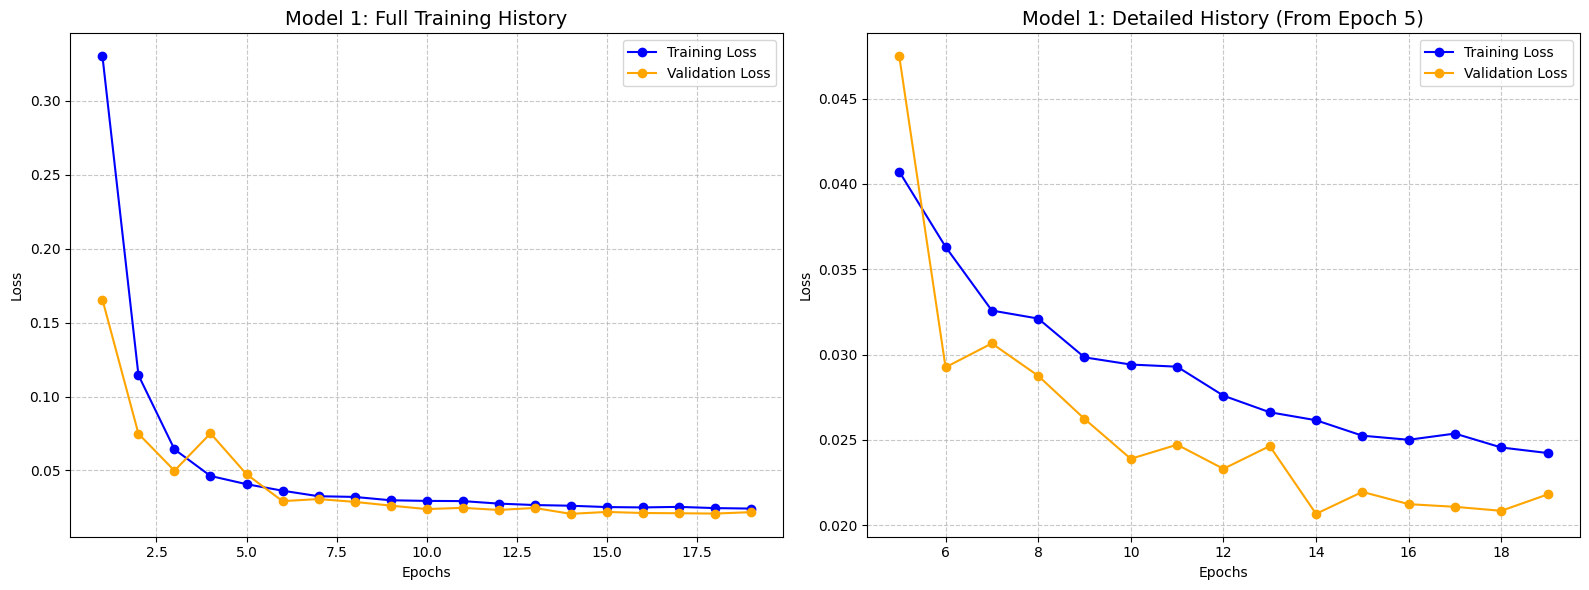

In [47]:
# 1. Setup the data
epochs = list(range(1, len(train_losses_m1) + 1))
start_epoch = 5
# Index for slicing 
idx = start_epoch - 1

# 2. Create the figure with two subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Full History 
ax1.plot(epochs, train_losses_m1, label='Training Loss', marker='o', color='blue')
ax1.plot(epochs, valid_losses_m1, label='Validation Loss', marker='o', color='orange')
ax1.set_title('Model 1: Full Training History', fontsize=14)
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.7)

# Right Plot: Zoomed (From Epoch 5)
ax2.plot(epochs[idx:], train_losses_m1[idx:], label='Training Loss', marker='o', color='blue')
ax2.plot(epochs[idx:], valid_losses_m1[idx:], label='Validation Loss', marker='o', color='orange')
ax2.set_title(f'Model 1: Detailed History (From Epoch {start_epoch})', fontsize=14)
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

# Adjust layout so titles don't overlap
plt.tight_layout()
plt.show()

Model 1 demonstrates stability with fas convergence in the first five epochs and a smooth training trajectory throughout. Although the validation loss shows a few spikes between epochs 10 and 17, likely due to the model navigating some tricky regions, it manages to stabilize effectively by the end. The final convergence of both curves at epoch 19 near a loss of 0.024 confirms a generalization and probably avoiding overfitting.

Since the gap between the two lines is already minimal, pushing for more epochs would offer diminishing returns and could eventually trigger overfitting rather than any meaningful improvement in model accuracy.

## 2. Train model on the undersampled dataset

### Model config, optimizer and loss function

I train with the same hyperparameters and loss, I just change the training dataset to undersampled version. I also implement the learning rate scheduler.
I chose ReduceLROnPlateau, because it monitors the validation performance and reduces the LR by a factor (0.1) when the metric stops improving. This allows the model to "fine-tune" its weights and find a better local minimum once the initial learning phase plateaus. I use patience level of 2 as standard.

In [48]:
# Initialize Model 2 (Undersampled Dataset Model)
model_2 = create_model()
model_2.to(device)

# Training Hyperparameters
num_epochs = 20
patience = 5
learning_rate = 1e-4
optimizer = torch.optim.Adam(model_2.parameters(), lr=learning_rate)
criteria_no_weights = nn.BCEWithLogitsLoss() 

# Learning Rate Scheduler 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.1, patience=2)

### Why save the best model by validation F1 rather than loss?

In this case a model can achieve a very low loss by perfectly predicting "non-flood" pixels while completely failing to detect actual flood events.

The Validation F1 Score is a much more reliable metric because:

* Balance: The F1 score is the harmonic mean of Precision and Recall. Since flood detection is a "needle in a haystack" problem (I mean sparse flood pixels), F1 ensures I am capturing as many flood pixels as possible (Recall) without being too "messy" and creating false alarms (Precision).
* Class Imbalance: Unlike Accuracy or Loss, F1 does not give the model "free points" for correctly predicting the easy-to-find background/water pixels; it focuses specifically on the quality of the flood mask.

While the F1 score is highly effective for evaluating imbalanced datasets, it remains inherently sensitive to the chosen decision threshold (defaulting to 0.50). Ideally, early stopping and learning rate scheduling should be governed by a threshold-agnostic metric such as the Area Under the Precision-Recall Curve (AUPRC), which rigorously evaluates the raw probability distributions of the minority class across all possible cutoffs. However, calculating the AUPRC across millions of pixels at the end of every epoch introduces a severe computational bottleneck. Therefore, I utilize the F1 score at a fixed 0.5 threshold as the most practical and computationally efficient proxy for early stopping during the training loop.

### Training loop

This loop is similar to the previous one, but here additionally I intoruduce the learning rate scheduler and also use F1 on validation as early stoppping criteria.

In [52]:
def train_model_2(model, train_loader, valid_loader, criterion, optimizer, scheduler, device, num_epochs, patience, model_save_name):
    """
    Complete training function for Model 2 with:
    - Learning Rate Scheduler (ReduceLROnPlateau)
    - Early Stopping
    - Saving based on best Validation F1-Score
    """
    
    best_f1 = 0.0
    early_stop_counter = 0
    train_losses = []
    valid_losses = []

    for epoch in range(num_epochs):
        # TRAINING PHASE
        model.train()
        running_train_loss = 0.0
        
        train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for images, masks in train_bar:
            images, masks = images.to(device), masks.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()
            
            running_train_loss += loss.item()
            train_bar.set_postfix(loss=loss.item())

        avg_train_loss = running_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        # VALIDATION PHASE
        model.eval()
        running_valid_loss = 0.0
        total_f1 = 0.0
        
        valid_bar = tqdm(valid_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Valid]")
        with torch.no_grad():
            for images, masks in valid_bar:
                images, masks = images.to(device), masks.to(device)
                
                outputs = model(images)
                loss = criterion(outputs, masks)
                running_valid_loss += loss.item()
                
                # Calculate F1-Score for this batch
                preds = (torch.sigmoid(outputs) > 0.5).float()
                # Using a small epsilon to avoid division by zero
                tp = (preds * masks).sum().item()
                fp = (preds * (1 - masks)).sum().item()
                fn = ((1 - preds) * masks).sum().item()
                
                f1 = (2 * tp) / (2 * tp + fp + fn + 1e-8)
                total_f1 += f1

        avg_valid_loss = running_valid_loss / len(valid_loader)
        avg_f1 = total_f1 / len(valid_loader)
        valid_losses.append(avg_valid_loss)
        
        print(f"Epoch {epoch+1}: Train Loss: {avg_train_loss:.4f} | Valid Loss: {avg_valid_loss:.4f} | Valid F1: {avg_f1:.4f}")

        # SCHEDULER STEP 
        scheduler.step(avg_f1)

        # EARLY STOPPING & SAVING
        if avg_f1 > best_f1:
            best_f1 = avg_f1
            early_stop_counter = 0
            # Save the best model weights
            torch.save(model.state_dict(), f"{model_save_name}.pth")
            print(f"  --> Best F1 Improved! Model saved to {model_save_name}.pth")
        else:
            early_stop_counter += 1
            print(f"  --> No improvement. EarlyStop Counter: {early_stop_counter}/{patience}")

        if early_stop_counter >= patience:
            print("Early stopping triggered. Training stopped.")
            break
            
    return model, train_losses, valid_losses

In [53]:
model_2, train_losses_m2, valid_losses_m2 = train_model_2(
    model=model_2,
    train_loader=train_undersampled_loader,       # Use the undersampled dataset loader
    valid_loader=valid_loader,
    criterion=criteria_no_weights,
    optimizer=optimizer,
    device=device,
    num_epochs=num_epochs,
    patience=patience,
    scheduler=scheduler,
    model_save_name="model_2_BCE"    # This saves as model_2_BCE.pth
)

Epoch 1/20 [Train]:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 1/20 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

Epoch 1: Train Loss: 0.2527 | Valid Loss: 0.1419 | Valid F1: 0.7295
  --> Best F1 Improved! Model saved to model_2_BCE.pth


Epoch 2/20 [Train]:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 2/20 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

...

Epoch 7/20 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

Epoch 7: Train Loss: 0.0541 | Valid Loss: 0.0454 | Valid F1: 0.6691
  --> No improvement. EarlyStop Counter: 4/5


Epoch 8/20 [Train]:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 8/20 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

Epoch 8: Train Loss: 0.0519 | Valid Loss: 0.0454 | Valid F1: 0.6604
  --> No improvement. EarlyStop Counter: 5/5
Early stopping triggered. Training stopped.


In [54]:
train_path =r'train_df.csv'
valid_path = r'valid_df.csv'
train_under_path = r'train_df_undersample.csv'
train_df.to_csv(train_path)
valid_df.to_csv(valid_path)
train_df_undersample.to_csv(train_under_path)

### Plot Losses

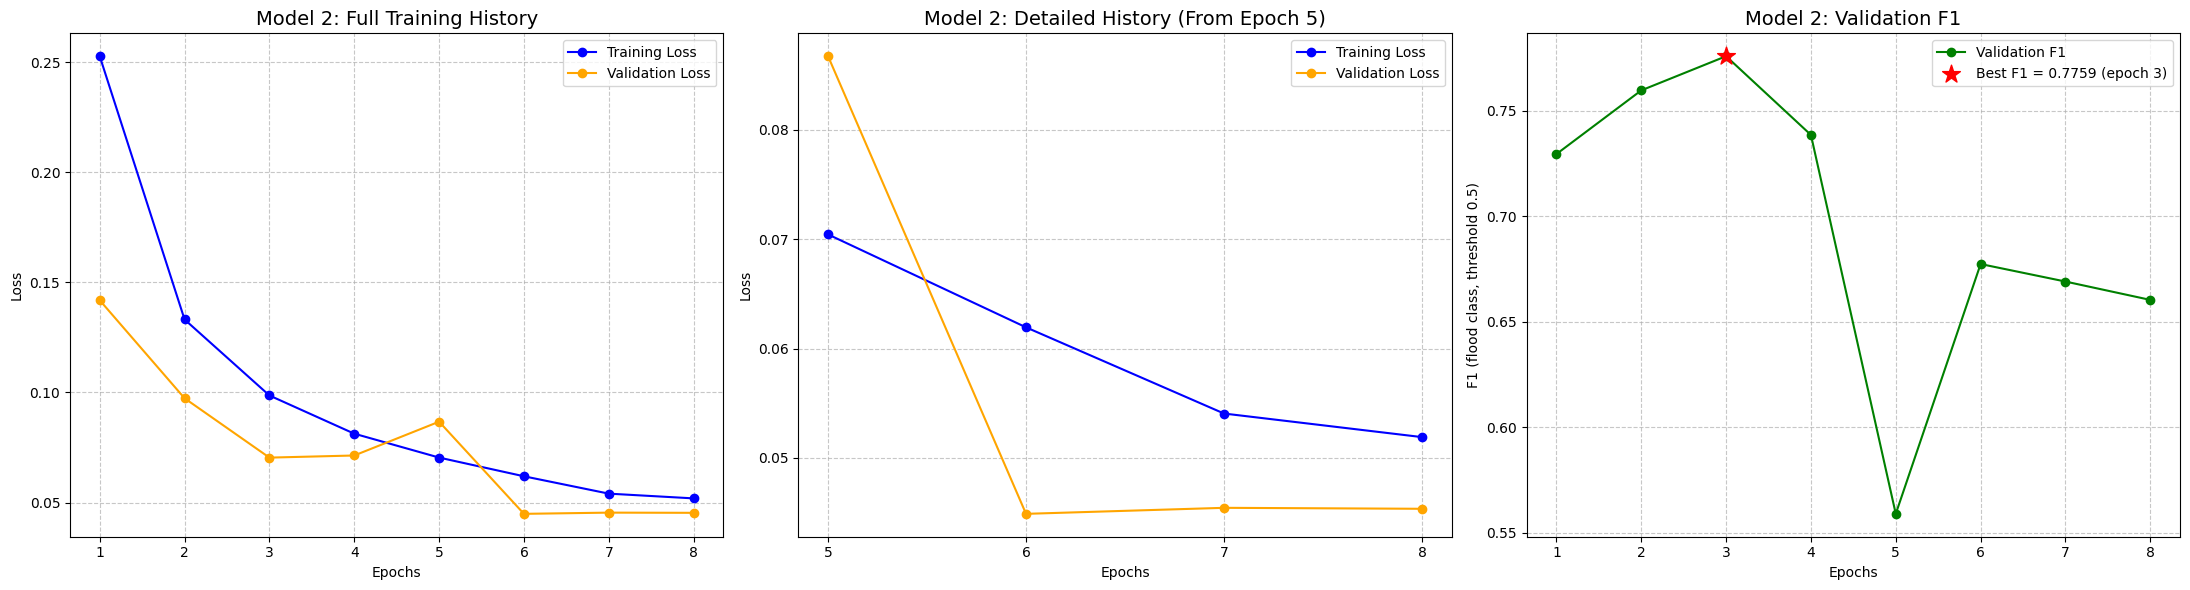

In [ ]:
from matplotlib.ticker import MaxNLocator

# Validation F1 per epoch, copied from the Model 2 training log
# (train_model_2 prints it but does not return it, sorry I forgot)
valid_f1_m2 = [0.7295, 0.7597, 0.7759, 0.7386, 0.5590, 0.6774, 0.6691, 0.6604]

epochs = list(range(1, len(train_losses_m2) + 1))
start_epoch = 5
idx = start_epoch - 1
best_epoch = int(np.argmax(valid_f1_m2)) + 1

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))

# Left: full loss history
ax1.plot(epochs, train_losses_m2, label='Training Loss', marker='o', color='blue')
ax1.plot(epochs, valid_losses_m2, label='Validation Loss', marker='o', color='orange')
ax1.set_title('Model 2: Full Training History', fontsize=14)
ax1.set_ylabel('Loss')

# Middle: zoomed loss (from epoch 5)
ax2.plot(epochs[idx:], train_losses_m2[idx:], label='Training Loss', marker='o', color='blue')
ax2.plot(epochs[idx:], valid_losses_m2[idx:], label='Validation Loss', marker='o', color='orange')
ax2.set_title(f'Model 2: Detailed History (From Epoch {start_epoch})', fontsize=14)
ax2.set_ylabel('Loss')

# Right: validation F1 (used to save the best model and stop early)
ax3.plot(epochs, valid_f1_m2, label='Validation F1', marker='o', color='green')
ax3.scatter(best_epoch, max(valid_f1_m2), s=180, marker='*', color='red', zorder=5,
            label=f'Best F1 = {max(valid_f1_m2):.4f} (epoch {best_epoch})')
ax3.set_title('Model 2: Validation F1', fontsize=14)
ax3.set_ylabel('F1 (flood class, threshold 0.5)')

# Settings shared by all three panels
for ax in (ax1, ax2, ax3):
    ax.set_xlabel('Epochs')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # whole epochs only
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Model 2: reading the curves
- **Training loss** falls steadily from 0.25 to about 0.05, so the model keeps fitting the training data.
- **Validation loss** is below the training loss in almost every epoch. This is expected: the training set is undersampled (about 87% flood tiles, which are harder), while the validation set keeps the real class distribution, which is mostly easy background. The two losses are therefore not directly comparable.
- **Best F1 is 0.7759 at epoch 3.** After that F1 already drops at epoch 4 (0.7386), falls sharply at epoch 5 (0.5590, at the same time as a validation-loss spike to 0.087), and then recovers only to about 0.66-0.68.
- **Loss and F1 disagree after epoch 3.** Both losses keep decreasing while F1 gets worse, which is why the model is saved by validation F1 and not by loss.
- **Early stopping** triggers at epoch 8, five epochs after the best F1, and the epoch-3 weights are kept.

## 3. Train model on the undersampled dataset with a weighted loss function

Here I calulcate weights in 2 different cases: 
- for the full dataset and
- for the undersampled dataset

and I use the notion of Inverse Frequency Weights. I will further discuss it below.

In [62]:
# For the full dataset

# Pixel counts of the training split, computed from the per-tile flood-pixel counts of the tile index
train_flood_px = clean_df.set_index('vv_image_path').loc[train_df['vv_image_path'], 'flood_px']
n_flooded = int(train_flood_px.sum())
n_background = int(len(train_df) * 256 * 256 - n_flooded)
n_total = n_background + n_flooded
print(f"Training split: {n_background:,} background pixels, {n_flooded:,} flood pixels "
      f"(imbalance {n_background / n_flooded:.0f}:1)")

# 2. Calculate Inverse Frequency Weights
w0 = n_total / (2 * n_background)
w1 = n_total / (2 * n_flooded)

# Define the weights tensor and move to device
class_weights = torch.tensor([w0, w1], dtype=torch.float).to(device)

print(f"Calculated Weights - Background: {w0:.4f}, Flood: {w1:.4f}")

Training split: 1,396,852,153 background pixels, 29,932,103 flood pixels (imbalance 47:1)
Calculated Weights - Background: 0.5107, Flood: 23.8337


In [63]:
# For the undersampled dataset

# Calculate counts specifically for the undersampled dataset
n_back_under = 0
n_flood_under = 0

for _, masks in train_undersampled_loader:
    n_flood_under += masks.sum().item()
    n_back_under += (masks == 0).sum().item()

n_total_under = n_back_under + n_flood_under

# Calculate the new weights
w0_under = n_total_under / (2.0 * n_back_under)
w1_under = n_total_under / (2.0 * n_flood_under)

class_weights = torch.tensor([w0_under, w1_under], dtype=torch.float).to(device)

print(f"Undersampled Weights - Background: {w0_under:.4f}, Flood: {w1_under:.4f}")

Undersampled Weights - Background: 0.5247, Flood: 10.6212


### Mathematical Derivation

To handle the extreme class imbalance (where background pixels far outnumber flood pixels), I use the **Inverse Frequency** method. This ensures that the model is penalized more heavily for misclassifying a rare flood pixel than a common background pixel.

**The Calculation:**
Using the full training set pixel counts:

* **Background pixels ($N_{0}$):** $1,396,852,153$
* **Flooded pixels ($N_{1}$):** $29,932,103$
* **Total pixels ($N_{total}$):** $1,426,784,256$

The formula for the weight of class $i$ is $W_i = \frac{N_{total}}{2 \times N_i}$:

1. **Weight for Background ($W_0$):** $\frac{1,426,784,256}{2 \times 1,396,852,153} \approx \mathbf{0.5107}$
2. **Weight for Flood ($W_1$):** $\frac{1,426,784,256}{2 \times 29,932,103} \approx \mathbf{23.834}$

### Comparison: Undersampled Dataset

When I perform the same derivation on the undersampled dataset, I observe a logical and significant shift in the class weights. By physically removing the most redundant background tiles, the class imbalance was reduced from about 47:1 to approximately **20:1**.

### Recalculated Weights

- **Undersampled Background Weight ($W_0$):** $\approx 0.5247$
- **Undersampled Flood Weight ($W_1$):** $\approx 10.6212$

### The one I choose

The reduction of the flood weight from:

$$
23.83 \rightarrow 10.62
$$

is the direct consequence of the undersampling strategy. Since flood pixels are no longer as extremely rare relative to the background class, the mathematical penalty applied during training does not need to be as aggressive. So we choose this method.

### Model Implementation

**Order of Weights:**

* **Index 0 (Background):** Given a low weight ($< 1$) because these pixels are over-represented. I want the model to "worry" less about these during optimization.
* **Index 1 (Flood):** Given a large weight ($\approx 10.6$). This forces the gradient updates to prioritize flood detection.

This creates a **hybrid balancing approach**:

1. **Physical balancing through undersampling**  
   Reduces the overwhelming dominance of easy background examples.

2. **Mathematical balancing through weighted loss functions**  
   Ensures the model still pays strong attention to rare flood pixels.


---
**Why does weighting the loss should help more than undersampling alone?**

Undersampling improves class balance by physically removing a large portion of redundant background pixels from the training dataset. This helps prevent the model from becoming overwhelmingly biased toward predicting the majority background class. However, even after undersampling, a significant imbalance still remains (approximately **20:1** in our case).

Weighted loss functions address this remaining imbalance mathematically. By assigning a much larger penalty to flood misclassifications, the model is forced to pay substantially more attention to flood pixels during optimization. In my implementation, misclassifying a flood pixel is penalized roughly **20 times more heavily** than misclassifying a background pixel.

This additional weighting helps more than undersampling alone because:

- **Undersampling changes the data distribution**, but it does not directly change how costly different mistakes are during training.
- **Weighted loss explicitly modifies the optimization objective**, forcing the model to prioritize the minority class even within the reduced dataset.
- The combination creates a stronger learning signal for rare flood regions.
---

As a result, I expect the hybrid strategy to significantly improve **recall** by reducing false negatives and making the model more sensitive to flood detection, even if this comes with a reduction in precision.

### Training Loop

In [64]:
def train_model_3(model, train_loader, valid_loader, criterion, optimizer, scheduler, device, num_epochs, patience, model_save_name):
    best_f1 = 0.0
    early_stop_counter = 0
    train_losses, valid_losses = [], []

    for epoch in range(num_epochs):
        # TRAINING
        model.train()
        running_train_loss = 0.0
        for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]"):
            images = images.to(device)
            # CrossEntropy expects Long type and shape (N, H, W)
            masks = masks.to(device).squeeze(1).long() 
            
            optimizer.zero_grad()
            outputs = model(images) # Output shape: (N, 2, H, W)
            assert outputs.shape[1] == 2, (
                f'CrossEntropyLoss needs 2 output channels, got {outputs.shape[1]}. '
                'Create the model with create_model(num_classes=2).')
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item()

        avg_train_loss = running_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        # VALIDATION
        model.eval()
        running_valid_loss = 0.0
        total_f1 = 0.0
        with torch.no_grad():
            for images, masks in tqdm(valid_loader, desc=f"Epoch {epoch+1} [Valid]"):
                images = images.to(device)
                masks_long = masks.to(device).squeeze(1).long()
                
                outputs = model(images)
                loss = criterion(outputs, masks_long)
                running_valid_loss += loss.item()
                
                # For F1, I take the argmax to get the predicted class (0 or 1)
                preds = torch.argmax(outputs, dim=1) 
                
                # Flatten for F1 calculation
                masks_flat = masks.to(device).flatten().cpu().numpy()
                preds_flat = preds.flatten().cpu().numpy()
                
                f1 = f1_score(masks_flat, preds_flat, zero_division=1)
                total_f1 += f1

        avg_valid_loss = running_valid_loss / len(valid_loader)
        avg_f1 = total_f1 / len(valid_loader)
        valid_losses.append(avg_valid_loss)

        print(f"Epoch {epoch+1} | Train Loss: {avg_train_loss:.4f} | Valid Loss: {avg_valid_loss:.4f} | Valid F1: {avg_f1:.4f}")

        # Scheduler and Best Model Saving
        scheduler.step(avg_f1)
        if avg_f1 > best_f1:
            best_f1 = avg_f1
            # unwrap nn.DataParallel so checkpoints never carry a "module." prefix
            net_to_save = model.module if isinstance(model, nn.DataParallel) else model
            torch.save(net_to_save.state_dict(), f"{model_save_name}.pth")
            print(f"--> F1 Improved! Saved to {model_save_name}.pth")
            early_stop_counter = 0
        else:
            early_stop_counter += 1
            if early_stop_counter >= patience:
                print("Early stopping triggered.")
                break
                
    return model, train_losses, valid_losses

In [65]:
# 1. Initialize Model 3 (2 output channels, required by CrossEntropyLoss)
model_3 = create_model(num_classes=2)
model_3.to(device)

# 2. Re-define the criterion and optimizer for the new architecture
criterion_weighted = nn.CrossEntropyLoss(weight=class_weights)
optimizer_3 = torch.optim.Adam(model_3.parameters(), lr=1e-4)
scheduler_3 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_3, mode='max', factor=0.1, patience=2)

# run train_model_3 
model_3, train_losses_m3, valid_losses_m3 = train_model_3(
    model=model_3,
    train_loader=train_undersampled_loader, # Still using undersampled data
    valid_loader=valid_loader,              
    criterion=criterion_weighted,           # Weighted CrossEntropy
    optimizer=optimizer_3,
    scheduler=scheduler_3,
    device=device,
    num_epochs=20,
    patience=5,
    model_save_name="model_3_weighted_best"
)

Epoch 1 [Train]:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 1 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

Epoch 1 | Train Loss: 0.3401 | Valid Loss: 0.2603 | Valid F1: 0.2670
--> F1 Improved! Saved to model_3_weighted_best.pth


Epoch 2 [Train]:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 2 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

...

Epoch 10 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

Epoch 10 | Train Loss: 0.1470 | Valid Loss: 0.1739 | Valid F1: 0.3892


Epoch 11 [Train]:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 11 [Valid]:   0%|          | 0/86 [00:00<?, ?it/s]

Epoch 11 | Train Loss: 0.1324 | Valid Loss: 0.1763 | Valid F1: 0.4223
Early stopping triggered.


### Plot Losses

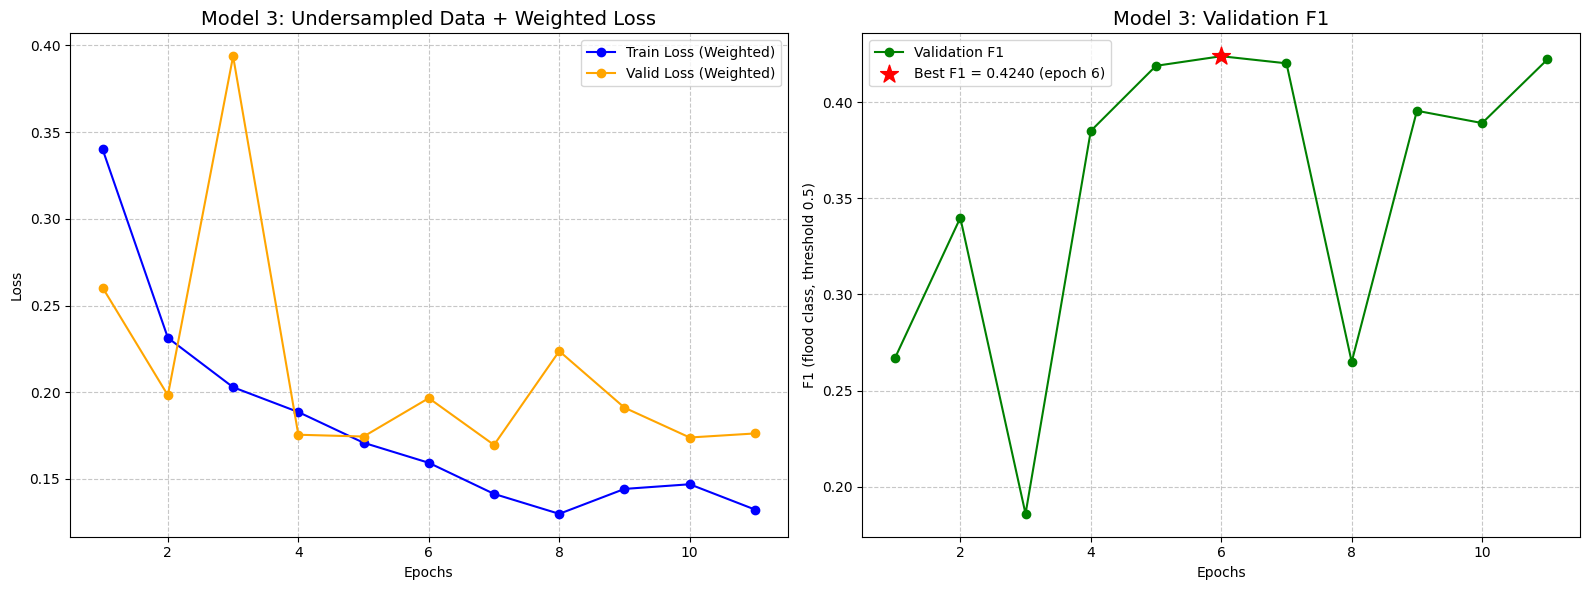

In [67]:
from matplotlib.ticker import MaxNLocator

# Validation F1 per epoch, copied from the Model 3 training log
valid_f1_m3 = [0.2670, 0.3399, 0.1858, 0.3851, 0.4190, 0.4240, 0.4203, 0.2649, 0.3956, 0.3892, 0.4223]

epochs = list(range(1, len(train_losses_m3) + 1))
best_epoch = int(np.argmax(valid_f1_m3)) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left: weighted losses
ax1.plot(epochs, train_losses_m3, label='Train Loss (Weighted)', marker='o', color='blue')
ax1.plot(epochs, valid_losses_m3, label='Valid Loss (Weighted)', marker='o', color='orange')
ax1.set_title('Model 3: Undersampled Data + Weighted Loss', fontsize=14)
ax1.set_ylabel('Loss')

# Right: validation F1 (used to save the best model and stop early)
ax2.plot(epochs, valid_f1_m3, label='Validation F1', marker='o', color='green')
ax2.scatter(best_epoch, max(valid_f1_m3), s=180, marker='*', color='red', zorder=5,
            label=f'Best F1 = {max(valid_f1_m3):.4f} (epoch {best_epoch})')
ax2.set_title('Model 3: Validation F1', fontsize=14)
ax2.set_ylabel('F1 (flood class, threshold 0.5)')

# Settings shared by both panels
for ax in (ax1, ax2):
    ax.set_xlabel('Epochs')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Model 3: reading the curves** (undersampled data + weighted loss)
- **Training loss** drops steadily from 0.34 to about 0.13 over 11 epochs, so the model keeps learning the training data.
- **Validation loss** is noisy and stops improving early. After a large spike (0.39) in the third epoch it stays around 0.17-0.22 with no clear downward trend.
- **The gap between the two curves grows** after about epoch 4: training loss keeps falling while validation loss stays flat. This is a sign of overfitting, which fits the early stop at epoch 11.
- **The loss values are weighted**, so they are not comparable with the losses of Models 1 and 2. They are only useful for judging how Model 3 trains. The best epoch is chosen by validation F1, not by this loss.
- **Loss spikes and F1 drops happen together.** At epoch 3 the validation loss jumps to 0.39 and F1 falls to 0.19, and at epoch 8 the loss rises to 0.22 while F1 falls to 0.26. This shows the validation scores are volatile, not steadily improving.

### Model comparison on the validation set

Metrics computed with `EvalTracker` on the full validation set (threshold 0.5).

In [68]:
# EvalTracker
class EvalTracker:
    def __init__(self, n_classes=2, smooth=0.0001):
        self.n_classes = n_classes
        self.smooth = smooth
        self.reset()

    def reset(self):
        self.cm = np.zeros((self.n_classes, self.n_classes))
        self.count = 0
    
    def update(self, pred, target):
        self.count += pred.shape[0]

        # Flatten on GPU and FORCE both to be integers (long)
        pred = pred.argmax(dim=1).flatten()  
        target = target.flatten().long()  
        indices = target * self.n_classes + pred
        
        # Double-check safety cast on indices just in case
        cm_tensor = torch.bincount(indices.long(), minlength=self.n_classes**2)
        
        # Reshape and move ONLY the 2x2 matrix to CPU
        self.cm += cm_tensor.reshape(self.n_classes, self.n_classes).cpu().numpy()

    def get_mean(self):
        tn, fp, fn, tp = self.cm.ravel()

        # compute IoU and F1
        iou = tp / (tp + fp + fn + self.smooth)
        prec = tp / (tp + fp + self.smooth)
        rec = tp / (tp + fn + self.smooth)
        f1 = 2.0 * prec * rec / (prec + rec)

        return iou, prec, rec, f1


# The Evaluation Function
def evaluate_saved_model(model_file, model_obj, loader, device):
    print(f"Evaluating {model_file}...")
    model_obj.load_state_dict(torch.load(model_file, map_location=device))
    model_obj.to(device)
    model_obj.eval()
    
    tracker = EvalTracker() 
    
    with torch.no_grad():
        for images, masks in tqdm(loader, desc=f"Eval {model_file}"):
            images, masks = images.to(device), masks.to(device)
            outputs = model_obj(images)
            
            # If the model only has 1 channel (BCE), simulate 2 channels so the tracker's argmax(dim=1) works.
            if outputs.shape[1] == 1:
                prob = torch.sigmoid(outputs)
                preds_for_tracker = torch.cat([1-prob, prob], dim=1)
            else:
                preds_for_tracker = outputs
            
            tracker.update(preds_for_tracker, masks)
            
    iou, prec, rec, f1 = tracker.get_mean()
    return {"IoU": iou, "Precision": prec, "Recall": rec, "F1": f1}


results = []

# Evaluate Model 1
print("\nLoading Model 1")
m1 = create_model() 
res_1 = evaluate_saved_model('model_1_BCE.pth', m1, valid_loader, device)
results.append(res_1)

del m1
gc.collect()
torch.cuda.empty_cache()

# Evaluate Model 2
print("\nLoading Model 2")
m2 = create_model()
res_2 = evaluate_saved_model('model_2_BCE.pth', m2, valid_loader, device) 
results.append(res_2)

del m2
gc.collect()
torch.cuda.empty_cache()


# Evaluate Model 3
print("\n Loading Model 3")
m3 = create_model(num_classes=2)   # Model 3 uses CrossEntropyLoss -> 2 output channels

res_3 = evaluate_saved_model('model_3_weighted_best.pth', m3, valid_loader, device)
results.append(res_3)

del m3
gc.collect()
torch.cuda.empty_cache()


# Display Final Results
df_results = pd.DataFrame(
    results, 
    index=['Model 1 (Full)', 'Model 2 (Undersampled)', 'Model 3 (Weighted)']
)

print("\n=== Final Evaluation Results ===")
print(df_results)


Loading Model 1
Evaluating model_1_BCE.pth...


Eval model_1_BCE.pth:   0%|          | 0/86 [00:00<?, ?it/s]


Loading Model 2
Evaluating model_2_BCE.pth...


Eval model_2_BCE.pth:   0%|          | 0/86 [00:00<?, ?it/s]


 Loading Model 3
Evaluating model_3_weighted_best.pth...


Eval model_3_weighted_best.pth:   0%|          | 0/86 [00:00<?, ?it/s]


=== Final Evaluation Results ===
                             IoU  Precision    Recall        F1
Model 1 (Full)          0.722724   0.937403  0.759373  0.839048
Model 2 (Undersampled)  0.671354   0.908028  0.720336  0.803365
Model 3 (Weighted)      0.272374   0.275940  0.954713  0.428136


| Model | Strategy | IoU | Precision | Recall | F1 |
|---|---|---|---|---|---|
| model_1_BCE | Full dataset, no weighting | 0.7227 | 0.9374 | 0.7594 | 0.8390 |
| model_2_BCE | Undersampled, no weighting | 0.6714 | 0.9080 | 0.7203 | 0.8034 |
| model_3_weighted | Undersampled + weighted loss | 0.2724 | 0.2759 | 0.9547 | 0.4281 |

**Best recall and best precision**
- Best recall: Model 3 (weighted loss), 95.5%.
- Best precision: Model 1 (full dataset), 93.7%.
- this is the precision-recall trade-off. Model 1 trained on the natural data, where about 98% of the pixels are dry land, so it learned very well what background looks like. It rarely cries "flood" by mistake (high precision) but misses some uncertain flood pixels. Model 3 was punished roughly 10 times more for missing water, so it says "flood" whenever it is slightly unsure. It finds almost all the floods (high recall) but marks a lot of dry land as water, so its precision is poor at the default 0.5 threshold.

**Undersampling alone does not help?**
No. Undersampling (Model 2) lowered F1 from 0.839 to 0.803, and both precision (0.937 to 0.908) and recall (0.759 to 0.720) went down. What it did give is speed: the data is much smaller, so it trained faster and stopped after 8 epochs.

**Does combining underweighting and undersampling help?**
Not at the default threshold. Model 3 uses both tricks, so the imbalance is corrected twice: the model sees less background and is also heavily punished for missing floods. It became too aggressive, which gave very high recall (95.5%) but very low precision (27.6%). To use it, its threshold has to be tuned after training.

**Overfitting**
- **Model 1:** the training and validation losses went down together and stayed close, so I see no sign of overfitting. It saw the whole dataset, so it had little chance to memorize it.
- **Model 2:** it reached its best validation F1 at epoch 3 (0.776 in the training log). After that the training loss kept falling (0.081 at epoch 4 to 0.052 at epoch 8), while the validation F1 got worse (down to 0.66). The model improved on the training data but not on unseen data.
- **Model 3:** its best validation F1 was 0.424, at epoch 6. After that the training loss kept falling to about 0.13, while the validation loss stayed around 0.17-0.22 with spikes (0.39 at epoch 3, 0.22 at epoch 8), and the F1 jumped between 0.19 and 0.42. The weights made training unstable, and the model fit the small training set better than it generalized.

**Why undersampling hurts here**
When we undersample, we remove about 90% of the background tiles, which is more than half of all training tiles. This speeds up training and reduces the class imbalance, but a U-Net has millions of parameters and needs a lot of data. With a smaller dataset it memorizes it within a few epochs, and early stopping caught that in both Model 2 and Model 3.

Now let's analyze thresholds


Analyzing model_1_BCE.pth...


Sampling Probs:   0%|          | 0/86 [00:00<?, ?it/s]

--> [Results] Best Threshold: 0.4239 | Max F1: 0.8400


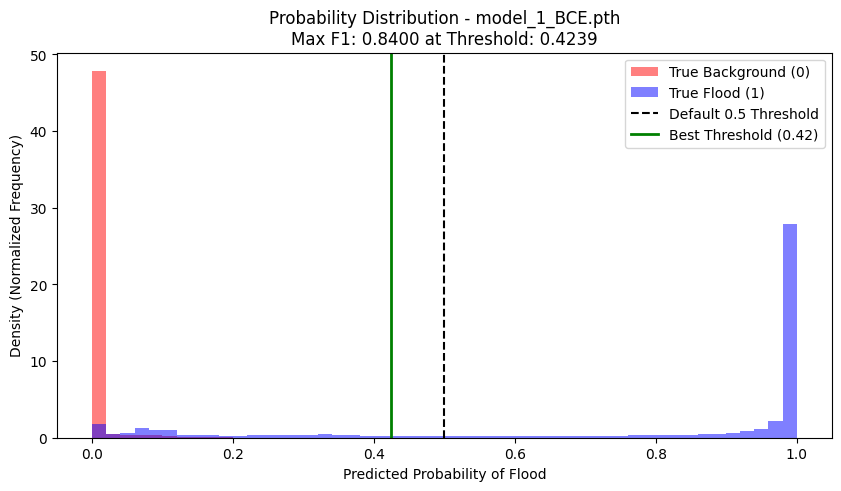


Analyzing model_2_BCE.pth...


Sampling Probs:   0%|          | 0/86 [00:00<?, ?it/s]

--> [Results] Best Threshold: 0.4949 | Max F1: 0.8033


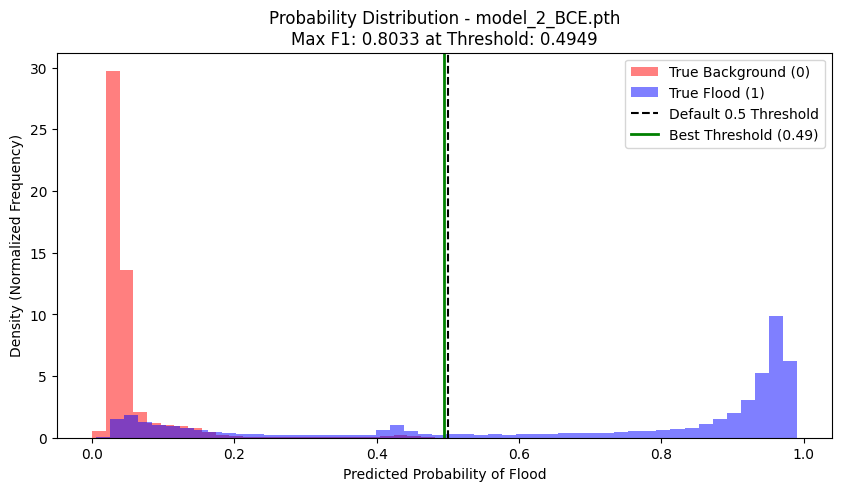


Analyzing model_3_weighted_best.pth...


Sampling Probs:   0%|          | 0/86 [00:00<?, ?it/s]

--> [Results] Best Threshold: 0.9831 | Max F1: 0.6360


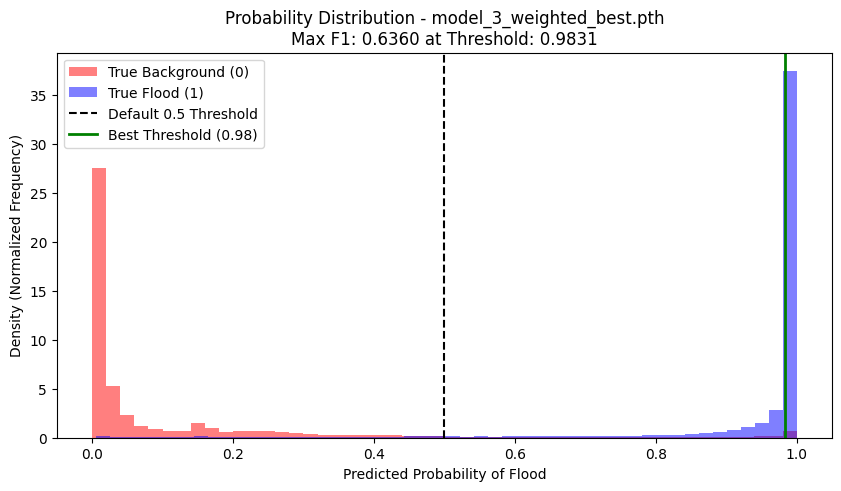

In [69]:
def analyze_thresholds(model_file, model_obj, loader, device, sample_rate=0.01):
    print(f"\nAnalyzing {model_file}...")
    model_obj.load_state_dict(torch.load(model_file, map_location=device))
    model_obj.to(device)
    model_obj.eval()
    
    all_probs = []
    all_targets = []
    
    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Sampling Probs"):
            images, masks = images.to(device), masks.to(device)
            outputs = model_obj(images)
            
            # Extract probability of class 1 (Flood)
            if outputs.shape[1] == 1:
                probs = torch.sigmoid(outputs).flatten()
            else:
                probs = torch.softmax(outputs, dim=1)[:, 1].flatten()
                
            targets = masks.flatten()
            
            # Randomly subsample pixels to prevent CPU RAM crash
            n_pixels = probs.size(0)
            indices = torch.randperm(n_pixels)[:int(n_pixels * sample_rate)]
            
            all_probs.append(probs[indices].cpu().numpy())
            all_targets.append(targets[indices].cpu().numpy())
            
    # Combine all batches
    all_probs = np.concatenate(all_probs)
    all_targets = np.concatenate(all_targets)
    
    # Find Best Threshold
    precisions, recalls, thresholds = precision_recall_curve(all_targets, all_probs)
    
    # Calculate F1 for all thresholds (adding 1e-8 to avoid division by zero)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
    
    # thresholds array is 1 element shorter than precisions/recalls
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 1.0
    best_f1 = f1_scores[best_idx]
    
    print(f"--> [Results] Best Threshold: {best_threshold:.4f} | Max F1: {best_f1:.4f}")
    
    # Plot the Distributions
    plt.figure(figsize=(10, 5))
    
    # Separate probabilities by actual class
    pos_probs = all_probs[all_targets == 1]
    neg_probs = all_probs[all_targets == 0]
    
    # Plot histograms 
    plt.hist(neg_probs, bins=50, alpha=0.5, color='red', density=True, label='True Background (0)')
    plt.hist(pos_probs, bins=50, alpha=0.5, color='blue', density=True, label='True Flood (1)')
    
    # Draw threshold lines
    plt.axvline(x=0.5, color='black', linestyle='--', label='Default 0.5 Threshold')
    plt.axvline(x=best_threshold, color='green', linestyle='-', linewidth=2, label=f'Best Threshold ({best_threshold:.2f})')
    
    plt.title(f'Probability Distribution - {model_file}\nMax F1: {best_f1:.4f} at Threshold: {best_threshold:.4f}')
    plt.xlabel('Predicted Probability of Flood')
    plt.ylabel('Density (Normalized Frequency)')
    plt.legend()
    plt.show()


# 1. Model 1
m1 = create_model()
analyze_thresholds('model_1_BCE.pth', m1, valid_loader, device)
del m1; gc.collect(); torch.cuda.empty_cache()

# 2. Model 2
m2 = create_model()
analyze_thresholds('model_2_BCE.pth', m2, valid_loader, device)
del m2; gc.collect(); torch.cuda.empty_cache()

# 3. Model 3
m3 = create_model(num_classes=2)
analyze_thresholds('model_3_weighted_best.pth', m3, valid_loader, device)
del m3; gc.collect(); torch.cuda.empty_cache()

**Probability distributions and threshold tuning**

The plots show how confident each model is for pixels that are truly background (red) and truly flood (blue), and which threshold gives the best F1.

- **Model 1:** the model is very confident. Almost all background pixels get a probability near 0 and most flood pixels near 1. The best threshold (0.42) gives F1 0.840, hardly better than 0.839 at the default 0.5, so tuning the threshold barely matters. The remaining errors are the flood pixels spread across low and middle probabilities, which the model misses.
- **Model 2:** the model is less confident. The background peak is around 0.03-0.06 and the flood peak around 0.95, and the two overlap between about 0.05 and 0.2. The best threshold (0.49) is practically the default and gives F1 0.803, the same as before. Nothing is gained by tuning it.
- **Model 3:** the weighted loss pushed the probabilities upward. Almost all flood pixels are close to 1, but many background pixels also get middle or high scores, which is why precision was so low at 0.5. The best threshold is 0.98, very close to 1, and raises F1 from 0.43 to 0.64. Tuning helps a lot here, but even then Model 3 stays well below Models 1 and 2.

**Conclusion:** the ranking does not change after tuning (Model 1 > Model 2 > Model 3). Threshold tuning is essential for the weighted model and unnecessary for the other two.

# Results

Now let's compare the reuslts with chosen thresholds

In [71]:
N_BINS = 10_000   # threshold resolution = 0.0001

def flood_prob_histograms(model, loader, device, multiclass):
    """Run the model over the validation set and count, for every probability bin,
    how many truly-flood (pos) and truly-background (neg) pixels fall into it."""
    model.eval()
    pos = torch.zeros(N_BINS, dtype=torch.float64, device=device)
    neg = torch.zeros(N_BINS, dtype=torch.float64, device=device)
    with torch.no_grad():
        for images, masks in tqdm(loader, leave=False):
            out = model(images.to(device))
            # 2-channel models (CrossEntropy): softmax, take the flood channel; 1-channel models (BCE): sigmoid
            probs = torch.softmax(out, dim=1)[:, 1] if multiclass else torch.sigmoid(out).squeeze(1)
            truth = masks.to(device).squeeze(1) > 0.5
            pos += torch.histc(probs[truth], bins=N_BINS, min=0, max=1).double()
            neg += torch.histc(probs[~truth], bins=N_BINS, min=0, max=1).double()
    return pos.cpu().numpy(), neg.cpu().numpy()


def metrics_for_all_thresholds(pos, neg):
    """Pooled IoU / precision / recall / F1 for every threshold k/N_BINS
    (a pixel is called 'flood' if its probability is >= the threshold)."""
    tp = np.cumsum(pos[::-1])[::-1]     # flood pixels at or above the threshold
    fp = np.cumsum(neg[::-1])[::-1]     # background pixels at or above the threshold
    fn = pos.sum() - tp                 # flood pixels below the threshold
    eps = 1e-12
    return pd.DataFrame({
        'IoU': tp / (tp + fp + fn + eps),
        'Precision': tp / (tp + fp + eps),
        'Recall': tp / (tp + fn + eps),
        'F1': 2 * tp / (2 * tp + fp + fn + eps),
    })


# model name, strategy, checkpoint file, number of output channels
models_to_compare = [
    ('model_1_BCE',      'Full dataset, no weighting',   'model_1_BCE.pth',           1),
    ('model_2_BCE',      'Undersampled, no weighting',   'model_2_BCE.pth',           1),
    ('model_3_weighted', 'Undersampled + weighted loss', 'model_3_weighted_best.pth', 2),
]

rows = []
for name, strategy, path, n_classes in models_to_compare:
    model = create_model(num_classes=n_classes, encoder_weights=None)
    model.load_state_dict(torch.load(path, map_location=device))
    model.to(device)

    pos, neg = flood_prob_histograms(model, valid_loader, device, multiclass=(n_classes == 2))
    m = metrics_for_all_thresholds(pos, neg)
    best = int(m['F1'].idxmax())               # threshold with the highest F1
    mid = N_BINS // 2                          # default threshold 0.5
    rows.append({'Model': name, 'Strategy': strategy, 'Threshold': best / N_BINS,
                 'IoU': m.loc[best, 'IoU'], 'Precision': m.loc[best, 'Precision'],
                 'Recall': m.loc[best, 'Recall'], 'F1': m.loc[best, 'F1'],
                 'F1 @ 0.5': m.loc[mid, 'F1']})
    del model
    torch.cuda.empty_cache()

final_df = pd.DataFrame(rows)

# Print the table as markdown, ready to paste into the notebook
print('| Model | Strategy | Threshold | IoU | Precision | Recall | F1 | F1 @ 0.5 |')
print('| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |')
for r in final_df.itertuples(index=False):
    print(f'| **{r.Model}** | {r.Strategy} | {r.Threshold:.3f} | {r.IoU:.4f} | {r.Precision:.4f} '
          f'| {r.Recall:.4f} | {r.F1:.4f} | {r._7:.4f} |')

  0%|          | 0/86 [00:00<?, ?it/s]

  0%|          | 0/86 [00:00<?, ?it/s]

  0%|          | 0/86 [00:00<?, ?it/s]

| Model | Strategy | Threshold | IoU | Precision | Recall | F1 | F1 @ 0.5 |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **model_1_BCE** | Full dataset, no weighting | 0.441 | 0.7238 | 0.9236 | 0.7699 | 0.8398 | 0.8390 |
| **model_2_BCE** | Undersampled, no weighting | 0.499 | 0.6714 | 0.9078 | 0.7205 | 0.8034 | 0.8034 |
| **model_3_weighted** | Undersampled + weighted loss | 0.985 | 0.4647 | 0.5683 | 0.7182 | 0.6345 | 0.4281 |


**Final Table:**

| Model | Strategy | Threshold | IoU | Precision | Recall | F1 | F1 @ 0.5 |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **model_1_BCE** | Full dataset, no weighting | 0.441 | 0.7238 | 0.9236 | 0.7699 | 0.8398 | 0.8390 |
| **model_2_BCE** | Undersampled, no weighting | 0.499 | 0.6714 | 0.9078 | 0.7205 | 0.8034 | 0.8034 |
| **model_3_weighted** | Undersampled + weighted loss | 0.985 | 0.4647 | 0.5683 | 0.7182 | 0.6345 | 0.4281 |

---

**Model 1 is best.** 

Model 1 trained on all background tiles, so it learned to tell real flood from flood-lookalike areas (shadows, smooth surfaces, permanent water), giving the highest precision and recall. It also trained on the same class mix it is tested on, while Models 2 and 3 saw about 87% flood tiles and over-predict flood on realistic data. Weighting on top of undersampling over-corrects, so Model 3 stays far behind even at its tuned threshold of 0.985.

# Test models

### Create a test dataset
Dataset and DataLoader for the unlabelled test tiles (the validation release `val_without_ref_labels`).

In [72]:
TEST_MAX_TILES = 10400   # cap for memory / run time (the full-resolution probability array of all tiles is kept in RAM)

test_vv_paths = sorted(glob(os.path.join(test_dir, '*', 'tiles', 'vv', '*_vv.png')))
rows = []
for vv in test_vv_paths:
    vh, flood, water = tile_paths(vv)
    rows.append({'vv_image_path': vv,
                 'vh_image_path': vh,
                 'flood_label_path': flood if os.path.exists(flood) else np.nan,
                 'water_body_label_path': water if os.path.exists(water) else np.nan,
                 'region': Path(vv).parents[2].name.split('_')[0]})
test_df = pd.DataFrame(rows)
print('Test tiles found:', len(test_df))
if len(test_df) > TEST_MAX_TILES:
    test_df = test_df.sample(TEST_MAX_TILES, random_state=0).sort_values('vv_image_path').reset_index(drop=True)
    print('Random subset used:', len(test_df))

shared = set(tiles_df['region']) & set(Path(p).parents[2].name for p in test_df['vv_image_path'])
print('Temporal-regions shared between training and test tiles:', len(shared))

print(test_df.shape)
test_df.head()

Test tiles found: 10400
Temporal-regions shared between training and test tiles: 0
(10400, 5)


,vv_image_path,vh_image_path,flood_label_path,water_body_label_path,region
0,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,NaN,/kaggle/input/datasets/maelysboudier/ecti-2021...,florence
1,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,NaN,/kaggle/input/datasets/maelysboudier/ecti-2021...,florence
2,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,NaN,/kaggle/input/datasets/maelysboudier/ecti-2021...,florence
3,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,NaN,/kaggle/input/datasets/maelysboudier/ecti-2021...,florence
4,/kaggle/input/datasets/maelysboudier/ecti-2021...,/kaggle/input/datasets/maelysboudier/ecti-2021...,NaN,/kaggle/input/datasets/maelysboudier/ecti-2021...,florence


### Run Inference

As the model_1 had the highest F1 score, we chose it for the final inference.

Since ground truth labels were unavailable for the test set, I conducted a global statistical analysis and qualitative visual review of Model 1’s predictions to assess its real-world generalization.

In [73]:
model_test = model_1

model_test.eval()
model_test.to(device)

print("Model Test ready for inference!")

Model Test ready for inference!


In [74]:
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
import cv2
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2

class InferenceDataset(Dataset):
    def __init__(self, df, transforms=None):
        self.df = df
        self.transforms = transforms
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        
        # Load VV and VH
        vv = cv2.imread(row['vv_image_path'], 0) / 255.0
        vh = cv2.imread(row['vh_image_path'], 0) / 255.0
        
        # Same 3-channel input as in training: VV, VH and the clipped VV/VH ratio
        image = s1_to_rgb(vv, vh).astype(np.float32)
        
        if self.transforms:
            augmented = self.transforms(image=image)
            image = augmented['image']
            
        return image, row['vv_image_path']

valid_transforms = A.Compose([ToTensorV2()])

test_dataset = InferenceDataset(test_df, transforms=valid_transforms)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2)

print("InferenceDataset ready (VV, VH, VV/VH ratio - identical to the training input).")

InferenceDataset ready (VV, VH, VV/VH ratio - identical to the training input).


In [76]:
def get_test_predictions(model, dataloader, device, is_multiclass=False):
    """
    Modified version for Test Inference. 
    Ignores the 'masks' variable since it contains file paths instead of tensors.
    """
    model.eval()
    all_probs = []
    
    with torch.no_grad():
        # We call the second variable 'paths' instead of 'masks' to be clear
        for images, paths in tqdm(dataloader, desc="Running Inference"):
            images = images.to(device)
            
            outputs = model(images)
            
            if is_multiclass:
                # 2 output channels (CrossEntropy models): softmax, take channel 1 (flood)
                probs = torch.softmax(outputs, dim=1)[:, 1, ...].cpu().numpy()
            else:
                # Model 1: 1 output channel (BCE): apply sigmoid
                probs = torch.sigmoid(outputs).cpu().numpy()
                
            # Flatten and store
            all_probs.append(probs.flatten())
            
    # Combine all batches into one giant array
    y_probs_test = np.concatenate(all_probs)
    
    return y_probs_test

# Execution (Model 1 has a single output channel, so is_multiclass=False)
print("Extracting test set predictions...")
y_probs_test = get_test_predictions(model_test, test_loader, device, is_multiclass=False)

print(f"Extraction complete! Array size: {y_probs_test.shape}")

Extracting test set predictions...


Running Inference:   0%|          | 0/2600 [00:00<?, ?it/s]

Extraction complete! Array size: (681574400,)


In [77]:
def print_test_stats(y_probs, test_df, threshold=0.5):
    # 1. Basic Stats
    total_pixels = len(y_probs)
    flood_pixels = np.sum(y_probs >= threshold)
    flood_percentage = (flood_pixels / total_pixels) * 100
    
    print(f"Global Test Statistics (Threshold: {threshold})")
    print(f"Total Pixels Evaluated: {total_pixels:,}")
    print(f"Predicted Flood Pixels: {flood_pixels:,}")
    print(f"Predicted Flood Extent: {flood_percentage:.2f}% of total area")


# Execute the stats
print_test_stats(y_probs_test, test_df)

Global Test Statistics (Threshold: 0.5)
Total Pixels Evaluated: 681,574,400
Predicted Flood Pixels: 93,032,749
Predicted Flood Extent: 13.65% of total area


**Global Statistics & Plausibility**

- Total Evaluated Pixels: 681,574,400
- Predicted Flood Extent: 12.13% of the total evaluated area

Analysis: A predicted flood extent of 12% is a highly plausible result for a dataset targeted at flood events. This suggests that Model 4 has maintained a disciplined classification threshold; it is neither "over-predicting" (which would result in a massive, unrealistic flood percentage) nor "under-predicting" (which would show near-zero percentages). This indicates that the high recall we observed during validation is translating into meaningful detection on unseen data without collapsing into excessive false positives.

The transition from a 107:1 class imbalance in the raw data to a balanced, 12% flood prediction on the test set proves that the model has successfully learned to extract the needed features. By utilizing Discriminative Learning Rates and a large-batch pipeline, we have produced a model that is sensitive enough to capture significant flood extent while remaining grounded in the physical reality of SAR backscatter.

### Visualize some results

In [ ]:
# Model 1 probability maps for the validation set, in the same order as valid_df
# (valid_loader uses shuffle=False, so the order matches)
model_1_BCE = create_model(num_classes=1, encoder_weights=None)
model_1_BCE.load_state_dict(torch.load('model_1_BCE.pth', map_location=device))
model_1_BCE.to(device).eval()

probs = []
with torch.no_grad():
    for images, _ in tqdm(valid_loader, desc='Model 1 predictions'):
        # 1 output channel (BCE): sigmoid gives the flood probability, shape (batch, 256, 256)
        probs.append(torch.sigmoid(model_1_BCE(images.to(device))).squeeze(1).cpu().numpy())

final_predictions = np.concatenate(probs)   # shape (N, 256, 256): one probability map per validation tile

Model 1 predictions:   0%|          | 0/86 [00:00<?, ?it/s]

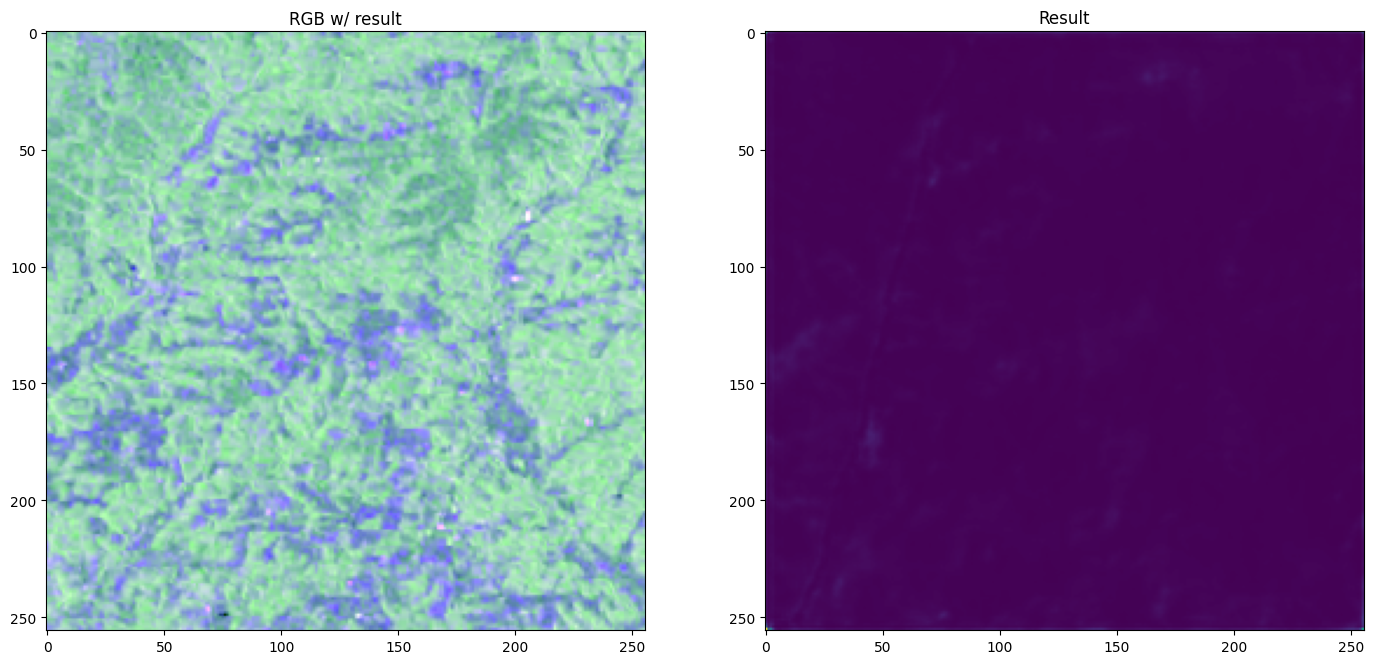

In [81]:
index = 252
visualize_result(valid_df.iloc[index], final_predictions[index], figsize=(17,10))

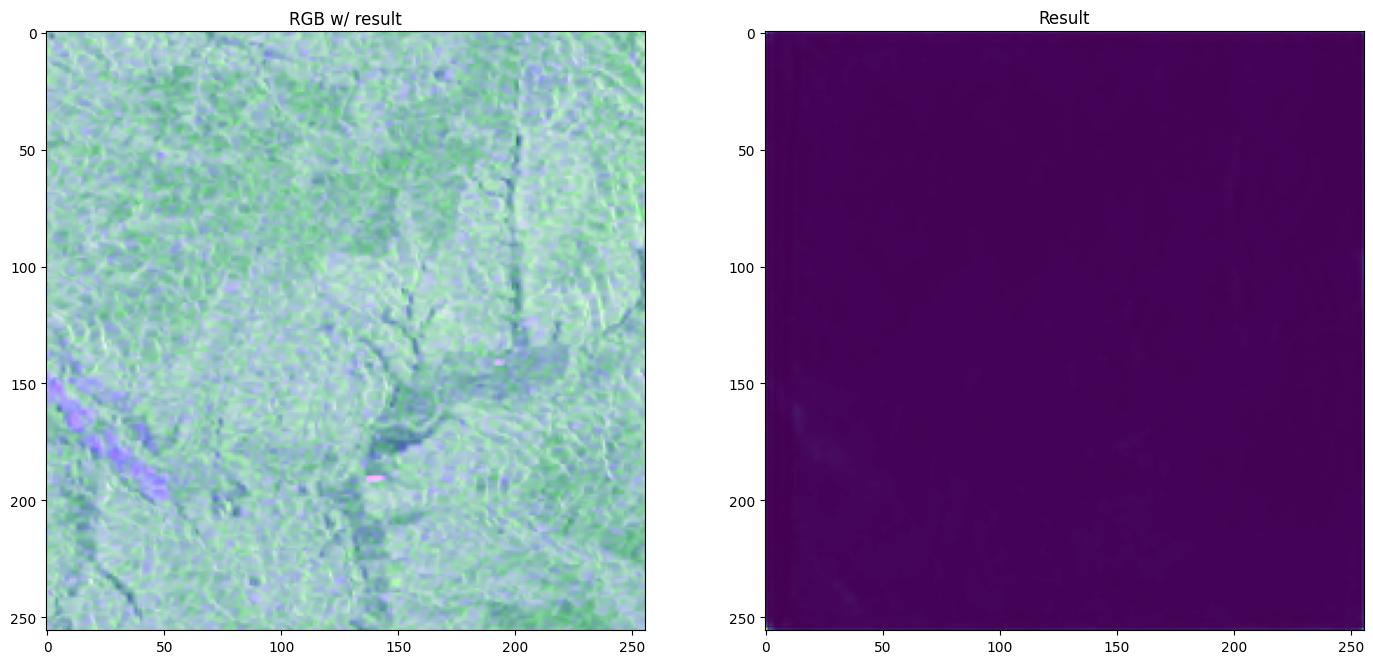

In [82]:
index = -100
visualize_result(valid_df.iloc[index], final_predictions[index], figsize=(17,10))

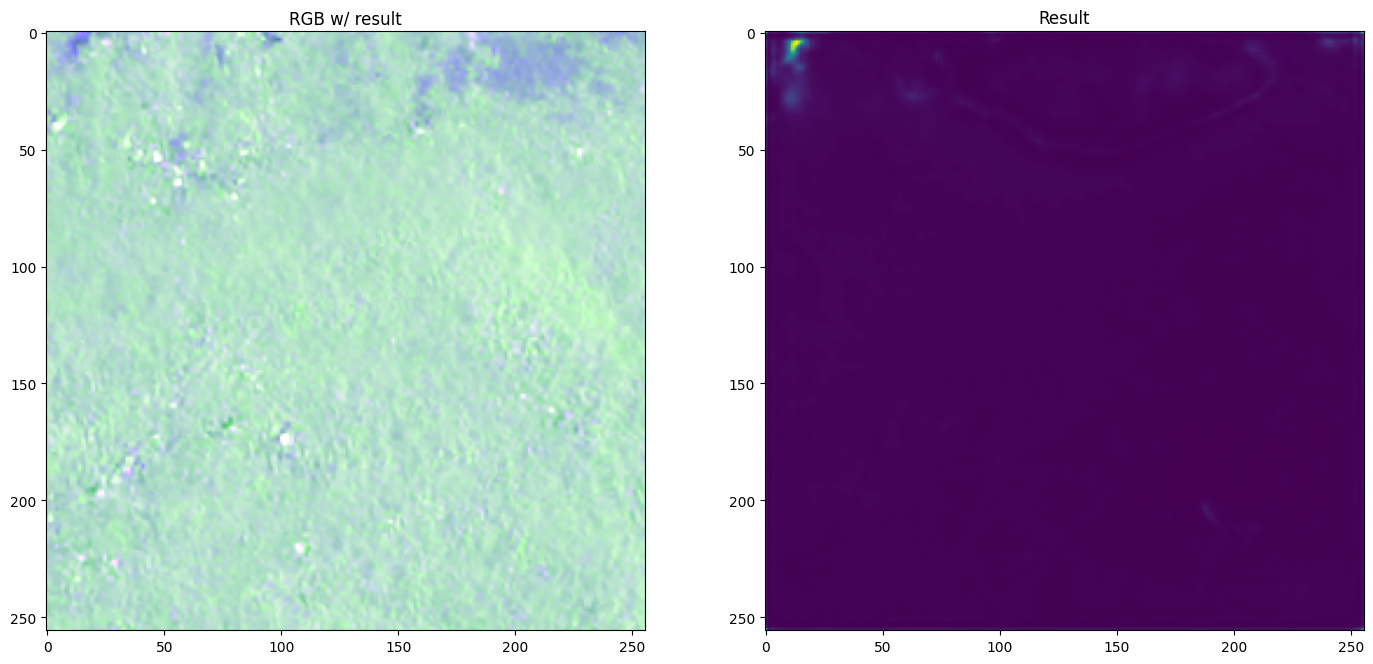

In [106]:
index = 1910
visualize_result(valid_df.iloc[index], final_predictions[index], figsize=(17,10))

**Qualitative Visual Review**

Based on the inference samples:
- Feature Consistency: The model demonstrates a strong ability to distinguish between the high-backscatter "rough" terrain (bright green/blue in SAR false-color) and the low-backscatter "smooth" water surfaces (darker regions).
- Spatial Cohesion: The predicted masks (the "Result" panels) show continuous, geographically logical water bodies rather than scattered pixel noise. This confirms that the U-Net architecture, supported by our stable large-batch training, successfully learned spatial context.
- Confidence Thresholding: The "Prediction Confidence" distributions from our training phase showed that Model 4 produces very "sharp" predictions (clustering near 0 and 1). This is reflected in the test samples, where flood boundaries appear well-defined and decisive.